# Lung cancer risk factors in US adults — project notebook

CS434 Data Science midterm (CRISP-DM phases 1–6). This notebook walks through the whole project by **calling
the functions of the pipeline scripts in `scripts/`**; it contains no analysis logic of its own, so every number
here is the number the scripts produce (and the number in the report).

By default (`REBUILD = False`) it reuses the files already built in `data/clean/` and `results/` and re-runs the
analysis functions on them (each one rewrites its own table or figure with identical content). Set
`REBUILD = True` to rebuild everything from the raw files first (`python run_all.py` does the same).

In [1]:
REBUILD = False          # True = rerun the whole pipeline from data/raw first (about 2 minutes)

import sys
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
import download_data, build_regional_data, build_clean_dataset as bcd, eda_analysis as eda
import feature_extraction_pca as fe, supplementary_analysis as sup

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)
from common import CLEAN, FIG, TAB
def show(name, width=800):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

if REBUILD:
    for step in (download_data, build_regional_data, bcd, eda, fe, sup):
        step.main()

df, mr, ctx = eda.load_data()          # clean dataset, model-ready dataset, regional table
print(f"clean: {df.shape}, model-ready: {mr.shape}, regional table: {ctx.shape}")

clean: (149928, 26), model-ready: (149928, 42), regional table: (20, 5)


## 1. Business understanding

**Context.** Lung cancer is the leading cause of cancer death in the United States. Low-dose CT screening is
offered only to a high-risk group (USPSTF: aged 50–80 with a heavy smoking history), so knowing which factors go
with lung cancer is a data problem upstream of the scan. Our target records a *past* diagnosis, so this midterm
studies risk factors and associations, not early detection.

**Problem statement.** Using NHIS 2019–2023 joined with regional pollution, smoking and cancer-registry data,
describe how smoking, age, chronic conditions, socio-demographic factors and the regional environment relate to
having had lung cancer, and prepare a clean, leakage-free feature set for a future risk model.

**Outcome.** Having ever been told by a doctor that one had lung cancer, self-reported by US adults in NHIS
2019–2023 (149,928 adults, 619 cases).

The five research questions below are printed from `eda_analysis.RESEARCH_QUESTIONS`, the same text that labels
the 18 hypothesis tests: RQ1 smoking (1 test), RQ2a age (1), RQ2b chronic conditions and e-cigarettes (7), RQ2c
socio-demographic and health factors (6), RQ3 regional context (3).

In [2]:
eda.research_questions()

OUTCOME
  Having ever been told by a doctor that one had lung cancer, self-reported by US adults in NHIS
  2019-2023 (149,928 adults, 619 cases).
RESEARCH QUESTIONS
  RQ1   Smoking. How much higher are the odds of a lung-cancer history among ever-smokers (current or
        former) than among never-smokers? How much of that odds ratio remains when ever- and
        never-smokers are compared within the same age group (Mantel-Haenszel over five age groups), and
        does its size differ between age groups (Breslow-Day)?
  RQ2a  Age. Are adults with a lung-cancer history older than those without, and by how much
        (Mann-Whitney U, rank-biserial r)? How does the survey-weighted rate change across the five age
        groups, alone and combined with smoking status?
  RQ2b  Chronic conditions and e-cigarettes. Which of five doctor-diagnosed conditions (COPD, heart
        disease, hypertension, diabetes, asthma), and ever using an e-cigarette, are associated with a
        lung-can

**Measurable success criteria** (fixed before the analysis; all eight are checked by code — the result is at the
end of Section 5):

1. 0 duplicate person IDs in the clean dataset.
2. 0 missing values in the model-ready dataset.
3. The regional join adds 0 rows.
4. Train and test keep the same lung-cancer rate (difference < 0.05 percentage points).
5. No test-set information in imputation, selection, scaling or PCA (asserted in `supplementary_analysis.py`).
6. Every research question (RQ1, RQ2a, RQ2b, RQ2c, RQ3) has at least one justified test with an effect size and a
   Holm-corrected p-value.
7. Every candidate feature has a written KEEP / DROP reason.
8. `CANEV_A` ("ever had any cancer") is never a feature.

## 2. Data understanding

### 2.1 Sources

| # | Dataset | Publisher | One row = | Used for | Combined by |
|---|---|---|---|---|---|
| 1 | NHIS Sample Adult files 2019–2023 | CDC / NCHS | one adult in one survey year | individual features and the target | stacking the 5 years |
| 2 | EPA AirData, annual concentration by monitor | US EPA | one monitor × pollutant × year | regional PM2.5 | state mean → region mean, joined on region + year |
| 3 | BRFSS prevalence, current smokers | CDC | one state × year × answer | regional adult smoking rate | region mean, joined on region + year |
| 4 | US Cancer Statistics, incidence by area | CDC + NCI | one area × year × sex × race × site | regional lung-cancer incidence | cases ÷ population × 100,000, joined on region + year |

NHIS only reveals the person's US Census region, so every regional measure is aggregated to region × year
(4 × 5 = 20 values) — context, not personal exposure.

In [3]:
ctx

,region,year,pm25_mean,smoking_rate,lung_cancer_incidence
0,Northeast,2019,5.98,14.49,77.7
1,Northeast,2020,6.20,13.19,69.0
2,Northeast,2021,6.85,12.66,73.7
3,Northeast,2022,5.80,11.99,74.4
4,Northeast,2023,7.18,10.22,75.1
5,Midwest,2019,7.25,17.12,82.2
6,Midwest,2020,7.04,16.53,75.4
7,Midwest,2021,8.23,15.18,79.3
8,Midwest,2022,6.93,14.68,79.9
9,Midwest,2023,8.73,13.47,80.4


The regional table has one row per region and year. The West stands out with a registry incidence of about
45–49 per 100,000 against 68–82 elsewhere; PM2.5 and the smoking rate vary less between regions and the
smoking rate falls every year.

### 2.2 Dataset composition at a glance

In [4]:
comp = sup.dataset_composition(df, mr)


0. DATASET COMPOSITION AT A GLANCE

1. adults per survey year
     item  adults  cases  rate_pct
     2019   31925    112      0.35
     2020   31513    131      0.42
     2021   29430    115      0.39
     2022   27594    116      0.42
     2023   29466    145      0.49
all years  149928    619      0.41

2. columns of the clean file
       item  n_columns                                                                                    columns
 identifier          1                                                                                  person_id
     weight          1                                                                              survey_weight
     target          1                                                                                lung_cancer
    numeric          2                                                                                  age, year
    ordinal          4                                      education, income_group, general

Each survey year contributes 27,594–31,925 adults and 112–145 cases, so no single year dominates. The 26 columns
of the clean file are 1 identifier, 1 survey weight, 1 target, 2 numeric, 4 ordinal, 3 nominal, 7 binary,
4 engineered and 3 regional columns. The final model matrix has 38 features — 8 demographic, 8 socio-economic,
6 smoking, 13 health and 3 regional — and the stratified split keeps the 0.41% case rate in both the 119,942
training rows and the 29,986 test rows. Every later rate states which of these adults it uses.

### 2.3 Target, missing values and quality issues


1. DATASET OVERVIEW AND DESCRIPTIVE STATISTICS
Adults: 149,928 | columns: 26 | years: [2019, 2020, 2021, 2022, 2023]
Lung cancer cases: 619
  Sample rate:     0.41%  (619 of 149,928 adults, unweighted)
  Population rate: 0.31%  (all 149,928 adults, weighted with NHIS survey weights)
Denominators: every rate, odds ratio and correlation below states its subset (n adults, n cases) and
whether it is survey-weighted. 'Unweighted' describes the sample; 'weighted' estimates the US adult population.
Why both? NHIS interviews some groups more than others; the weights correct this.

Numeric columns - centre, spread and shape (all 149,928 adults with the value known, unweighted):
                        mean  median   mode    std    IQR    min    max  skewness  kurtosis_excess
age                    52.80   54.00  85.00  18.36  31.00  18.00  85.00     -0.05            -1.08
comorbidity_count       0.73    0.00   0.00   0.91   1.00   0.00   5.00      1.29             1.54
pm25_mean               

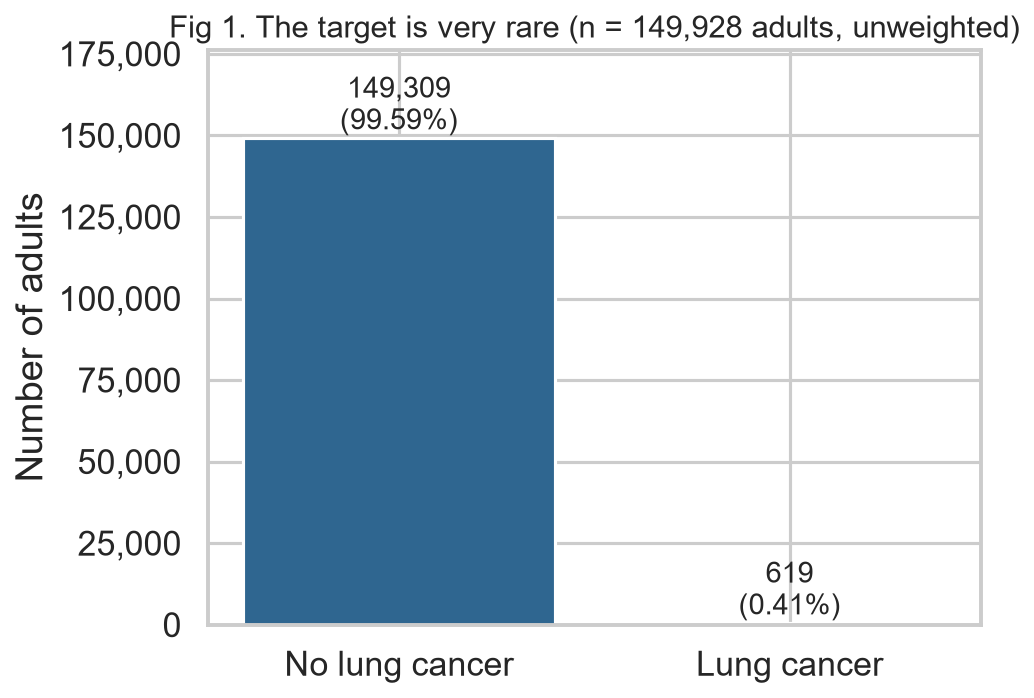

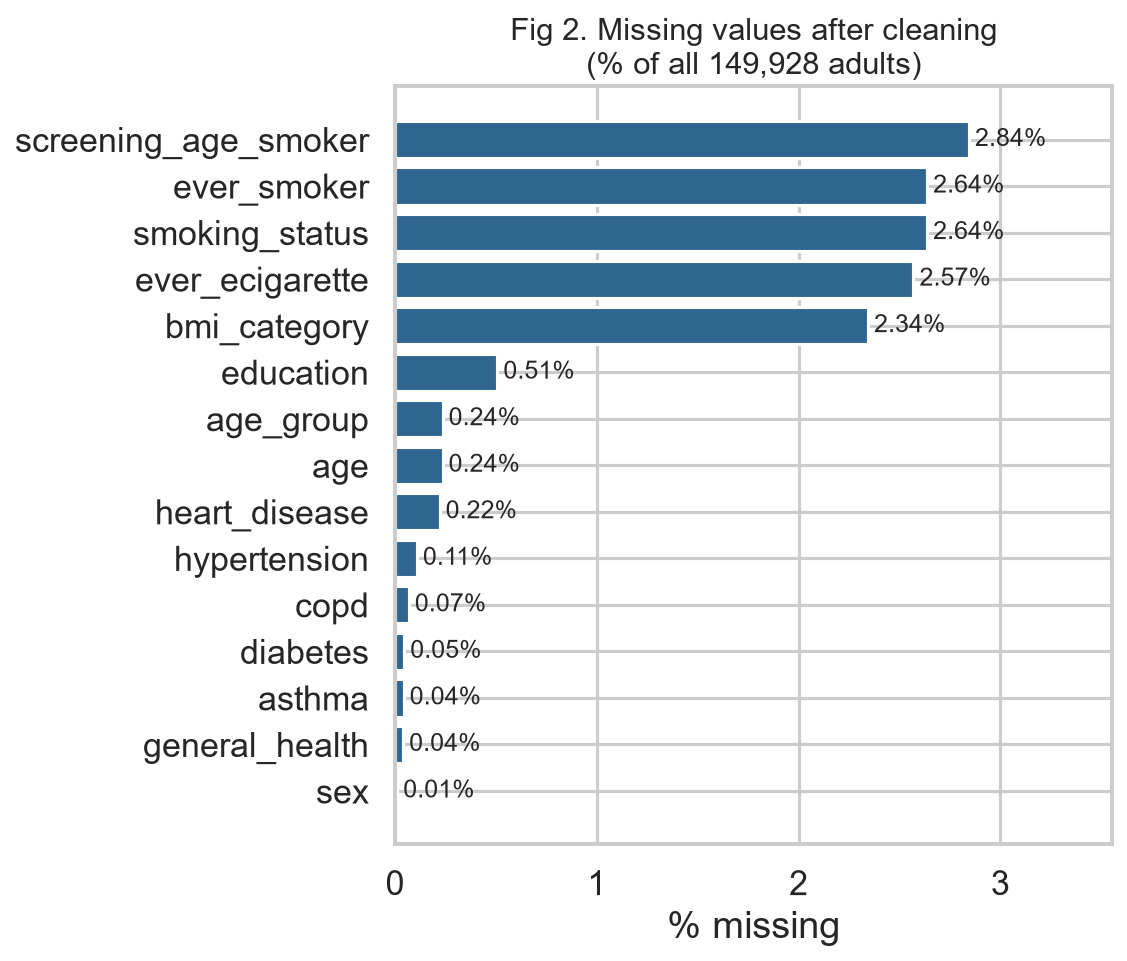

In [5]:
miss_tab = eda.overview(df)
show("fig01_class_balance", 500)
show("fig02_missing_values", 600)

Only 619 of 149,928 adults (0.41%; 0.31% after survey weighting) have had lung cancer, so a model that always
says "no" is 99.59% accurate — accuracy is useless here. No column is more than 2.84% missing, and for none of the
five columns above 1% is "value missing" linked to the target (all Holm p = 1.00). The tests have little power
(13–19 cases per missing group), so we still keep explicit "unknown" categories and flags.


1b. UNIVARIATE ANALYSIS (one variable at a time)
Age: mean 52.8, median 54, SD 18.4, skewness -0.05, excess kurtosis -1.08
Normality tests on age: Shapiro-Wilk (5,000-person sample) p = 5.71e-33; D'Agostino K2 (all adults) p < 1e-300
Reading: age is NOT normal (flat with two humps, and a pile-up at 85 = '85 or older'); the Q-Q plot in Fig 4 shows
the S-shape of a flat distribution. -> use rank-based tests (Mann-Whitney, Spearman) for age.

Categorical distributions saved (results/tables/categorical_distributions.csv). Largest groups:
  Sex                              Female (54.3%)
  Race / ethnicity                 White (67.5%)
  Education                        Some college (28.5%)
  Family income vs poverty line    High (42.9%)
  BMI category                     Overweight (34.5%)
  Self-rated general health        Very good (34.1%)
  Smoking status                   Never (62.3%)
  US region                        South (36.2%)


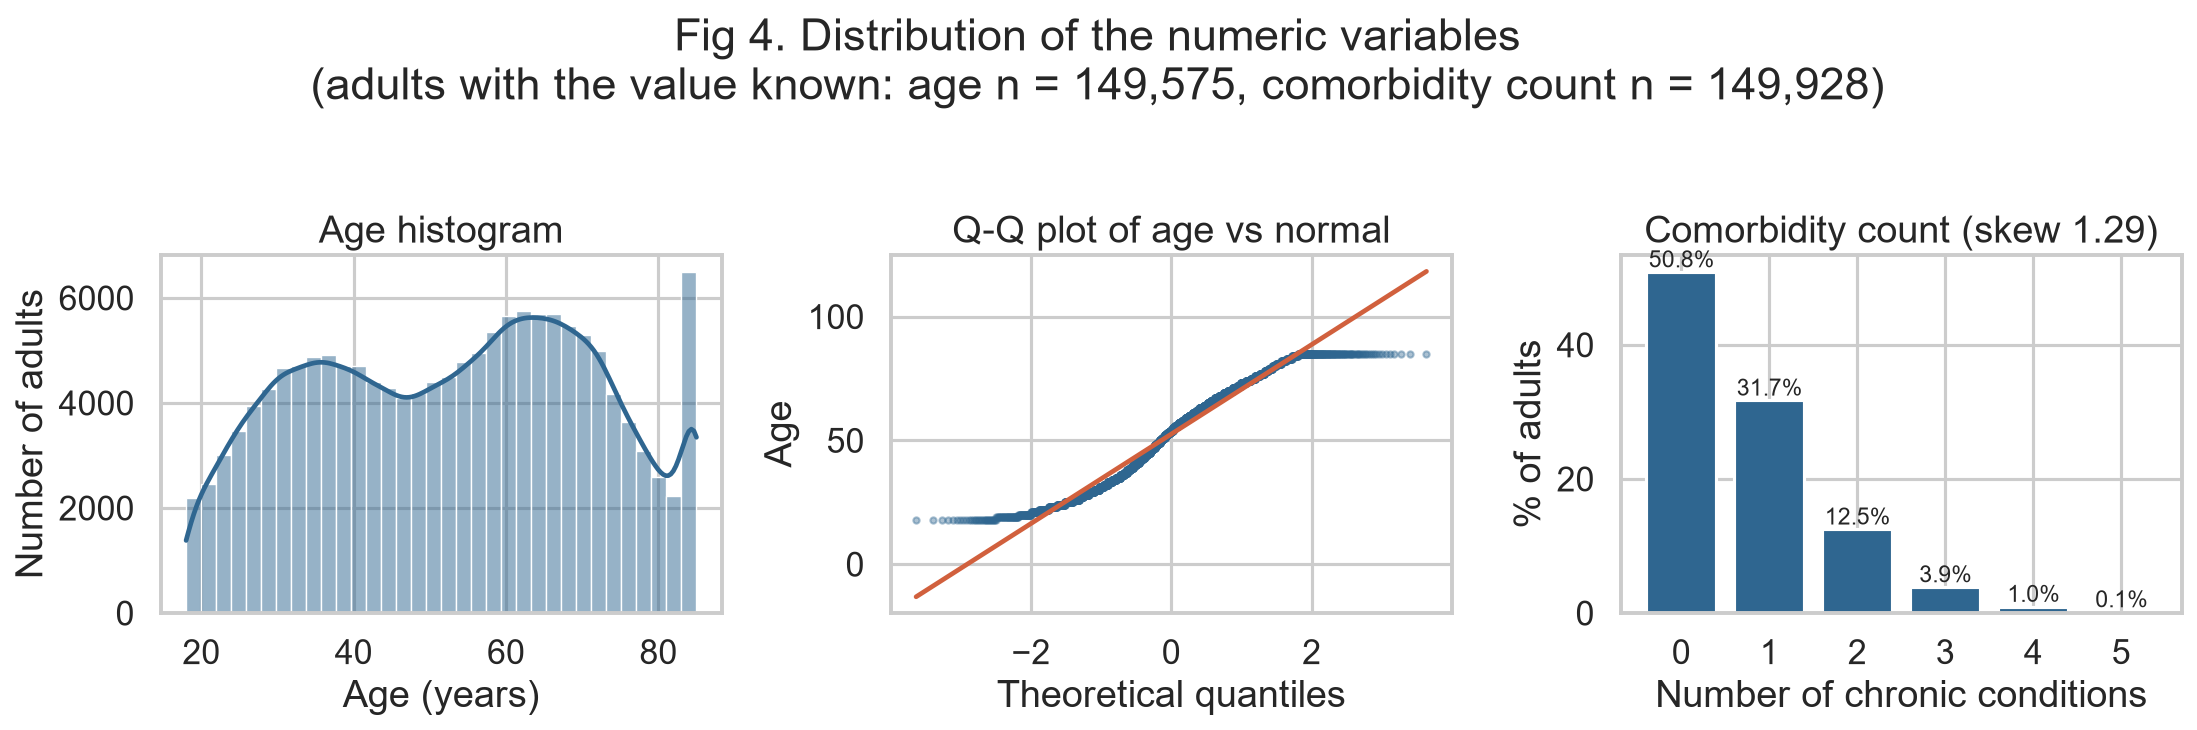

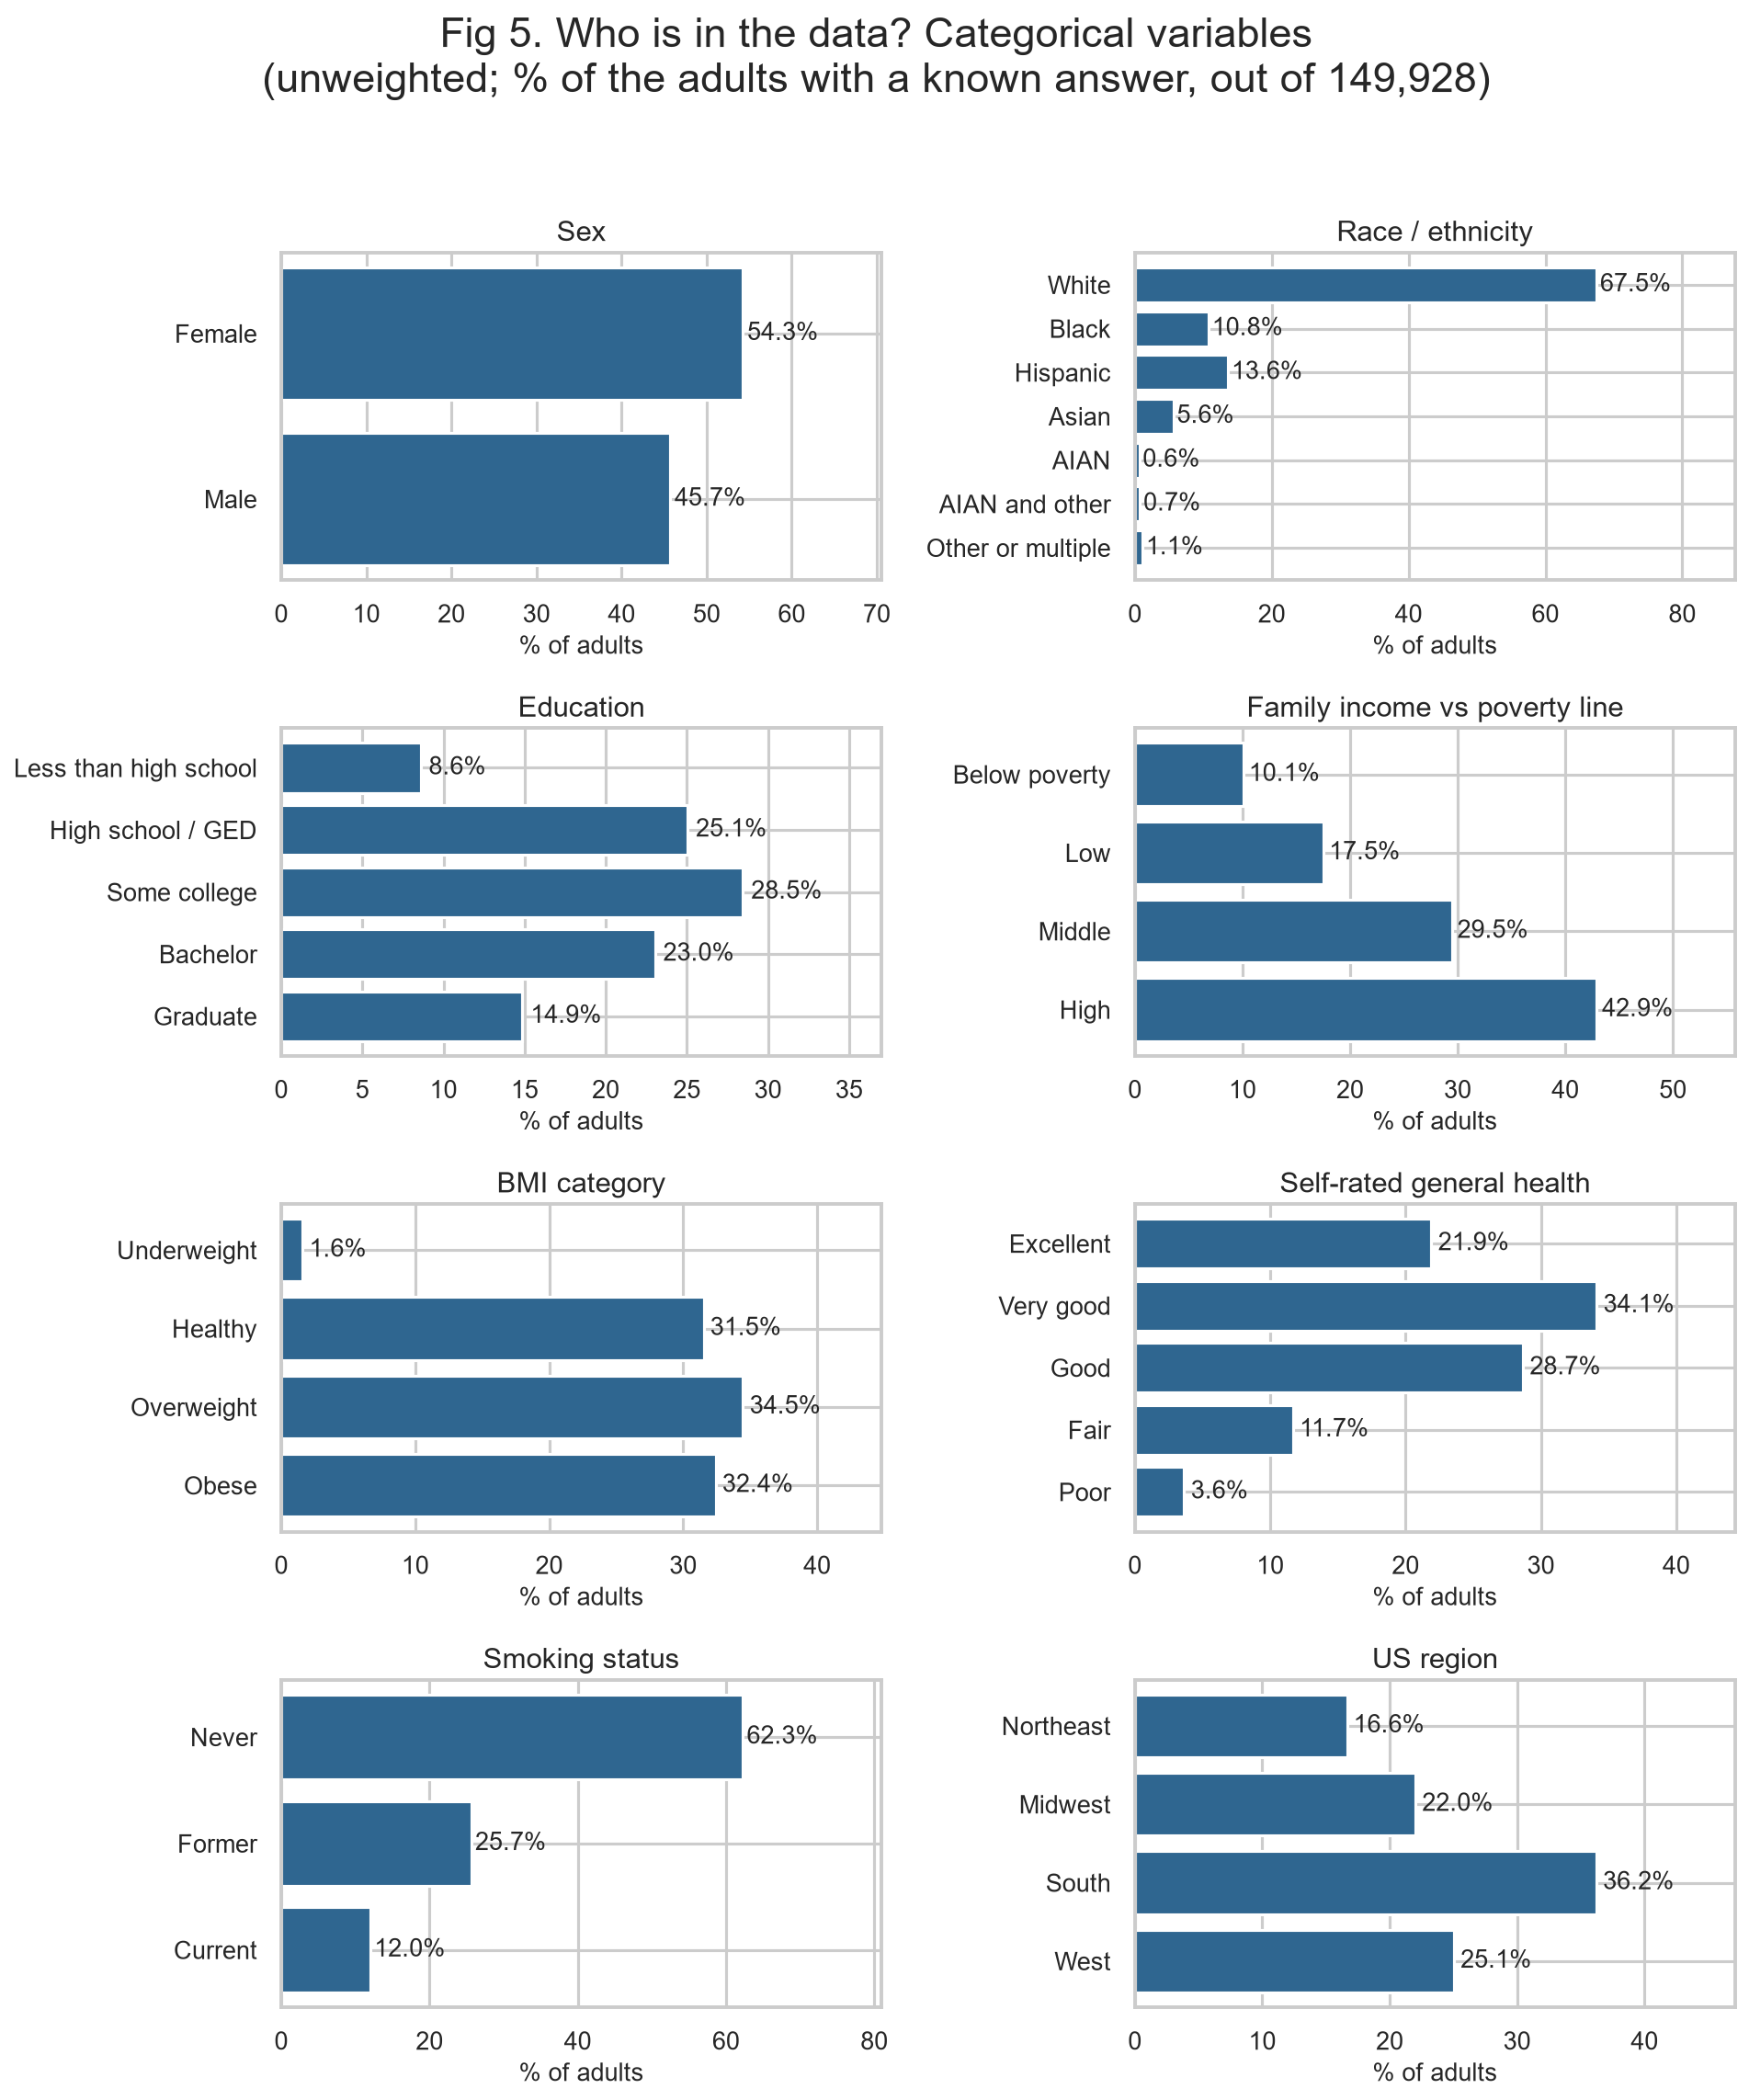

In [6]:
sw = eda.univariate(df)
show("fig04_numeric_distributions", 900)
show("fig05_categorical_distributions", 700)

Age is not normal (flat with two humps and a pile-up at the 85 top-code; Shapiro–Wilk p = 5.7e-33), so age is
tested with rank-based methods. The comorbidity count is right-skewed (half of adults have none of the five
conditions), but it is a small count, so no transformation is needed.

In [7]:
prof = sup.population_profile(df)
prof[prof.variable == "smoking_status"]


1. WHO IS IN THE DATA? Every category: adults, share, cases, rates
149,928 adults, 619 with a lung-cancer history. 'Weighted' = NHIS survey weights (US adult population).
Unknown = the person did not give a usable answer (kept as its own row so the counts add up).

sex
category  adults  pct_of_sample  pct_of_population_weighted  cases  non_cases  rate_sample_pct  rate_weighted_pct  mean_age
  Female   81360          54.27                       51.52    354      81006             0.44               0.32      53.6
    Male   68552          45.72                       48.47    265      68287             0.39               0.30      51.9
 Unknown      16           0.01                        0.01      0         16             0.00               0.00      37.6

age_group
category  adults  pct_of_sample  pct_of_population_weighted  cases  non_cases  rate_sample_pct  rate_weighted_pct  mean_age
   18-44   54481          36.34                       45.77     13      54468             0.02    

,variable,category,adults,pct_of_sample,pct_of_population_weighted,cases,non_cases,pct_of_all_cases,rate_sample_pct,rate_weighted_pct,mean_age
35,smoking_status,Never,90937,60.653780,63.478731,107,90830,17.285945,0.117664,0.081286,50.254600
36,smoking_status,Former,37452,24.979990,21.958969,367,37085,59.289176,0.979921,0.812891,59.746309
37,smoking_status,Current,17586,11.729630,11.728857,127,17459,20.516963,0.722165,0.597982,51.142841
38,smoking_status,Unknown,3953,2.636599,2.833443,18,3935,2.907916,0.455350,0.316298,52.926873


The population profile gives adults, shares, cases and sample / weighted rates for every category; for example,
former smokers are 25.0% of the sample but hold 367 of the 619 cases (0.98% sample, 0.81% weighted rate), and
they are older (mean age 59.7) than current (51.1) and never-smokers (50.3). The full table is
`results/tables/population_profile.csv` (report Tables 5–9).

### 2.4 The rejected dataset

The project started from `lung_cancer_combined_22457.csv`, which copies the 309-person Kaggle "Lung Cancer"
survey: 2,573 rows are exact repeats, the first 1,455 rows are all negative (row order predicts the label), and
once the repeats are removed no question is linked to lung cancer (all Cramér's V < 0.02). It is kept in
`data/raw/other/` for transparency only and is never read by the pipeline.

## 3. Data preparation

`build_clean_dataset.py` stacks the five NHIS years, builds `person_id` (year + household), derives the target
from `CANEV_A` + `LUNGCAN_A` (unknown answers removed, never imputed), turns the hidden 7/8/9 codes into real
missing values, adds the engineered columns, joins the regional table and runs the checks. The step-by-step
effect is logged in `data/clean/before_after_summary.csv`.

In [8]:
pd.read_csv(CLEAN / 'before_after_summary.csv')

,step,rows,columns,missing_cells,what_changed
0,1. Load + stack 5 years,150220,20,131400,5 yearly files stacked; 20 needed columns kept (LUNGCAN_A is blank by design for people who never had cancer)
1,2. Remove duplicates,150220,21,131400,0 duplicate person IDs removed
2,3. Build target,149928,22,131217,292 rows with unknown answer removed
3,4. Recode codes -> values,149928,19,13235,"number codes turned into words; e.g. 4,424 'unknown' codes in 4 key columns -> missing"
4,5. New columns,149928,23,21805,"added age_group, ever_smoker, screening_age_smoker, comorbidity_count"
5,5b. Join regional table,149928,26,21805,"3 columns added (pm25_mean, smoking_rate, lung_cancer_incidence); 0 rows added"
6,5c. Outlier check,149928,26,21805,IQR check on 6 numeric columns; all values plausible -> kept
7,6. Checks + save clean file,149928,26,21805,"0 duplicate IDs, ages 18-85, missing values listed"
8,7. Encode + fill gaps (train only),149928,71,0,"one-hot encoding, training-median filling, 'unknown' flags -> 0 missing"
9,8. Feature selection,149928,42,0,29 redundant / near-constant / near-duplicate / linearly dependent features dropped; 38 kept (max VIF 7.5)


Only 292 of 150,220 rows were lost (unknown target), the join kept 149,928 rows before and after, and the
model-ready file has 0 missing cells. Step 8 (feature selection) now ends with 38 features and a maximum VIF of
7.5, and step 9 standardises 4 numeric columns.

In [9]:
outliers = bcd.outlier_check(df)
outliers[["column", "lower_bound", "upper_bound", "n_outliers", "pct_outliers", "decision"]]


STEP 5c - Outlier check (IQR rule: below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR)
  age                    bounds [-9.5, 114.5]  outliers: 0 (0.00%)  -> KEEP - every age 18-85 is a real adult; 85 means '85 or older' (NHIS top-code), not an error
  comorbidity_count      bounds [-1.5, 2.5]  outliers: 7,451 (4.97%)  -> KEEP - a count from 0 to 5; high values are real people with several diseases
  pm25_mean              bounds [5.3, 9.2]  outliers: 0 (0.00%)  -> KEEP - official EPA measurements; only 20 region-year values, none impossible
  smoking_rate           bounds [8.7, 20.7]  outliers: 0 (0.00%)  -> KEEP - official CDC percentages between 0 and 100
  lung_cancer_incidence  bounds [10.4, 114.4]  outliers: 0 (0.00%)  -> KEEP - official registry rates; differences between regions are real
  survey_weight          bounds [-4883.8, 19849.6]  outliers: 7,431 (4.96%)  -> KEEP - NHIS design weight, used for population estimates only, not as a feature
  Box plots saved to results/figures/f

,column,lower_bound,upper_bound,n_outliers,pct_outliers,decision
0,age,-9.500000,114.500000,0,0.00,"KEEP - every age 18-85 is a real adult; 85 means '85 or older' (NHIS top-code), not an error"
1,comorbidity_count,-1.500000,2.500000,7451,4.97,KEEP - a count from 0 to 5; high values are real people with several diseases
2,pm25_mean,5.275000,9.235000,0,0.00,"KEEP - official EPA measurements; only 20 region-year values, none impossible"
3,smoking_rate,8.690000,20.690000,0,0.00,KEEP - official CDC percentages between 0 and 100
4,lung_cancer_incidence,10.400000,114.400000,0,0.00,KEEP - official registry rates; differences between regions are real
5,survey_weight,-4883.823875,19849.595125,7431,4.96,"KEEP - NHIS design weight, used for population estimates only, not as a feature"


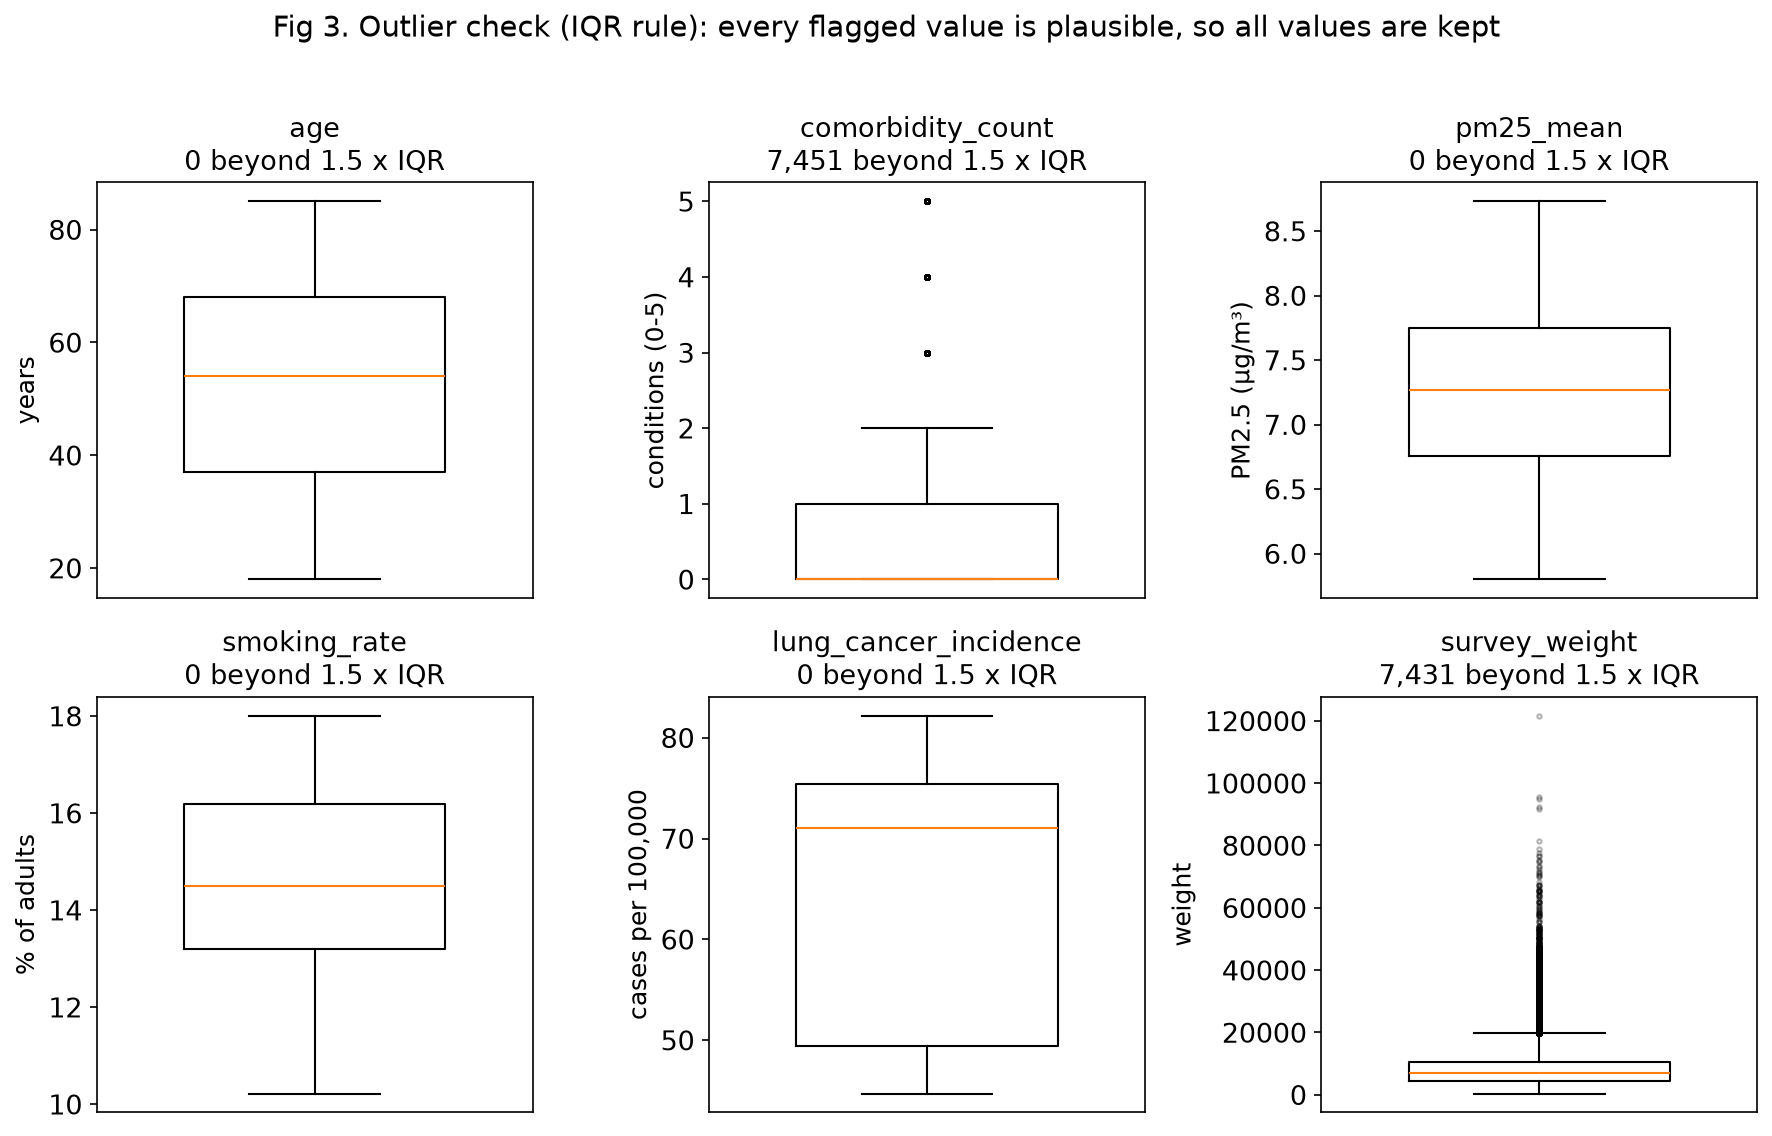

In [10]:
show("fig03_outlier_boxplots", 800)

The IQR rule flags 7,451 adults with three or more conditions and 7,431 regional values, but every flagged
value is real (a person with several diseases, an official registry rate), so nothing is removed: removing them
would delete exactly the older, sicker adults among whom lung cancer is concentrated.

**Leakage prevention.** The 80/20 split (stratified on the target, seed 42) is made before anything is fitted;
imputation values, every feature-selection rule, the VIF step, the scaler and the PCA use training rows only.
The check below refits the scaler on the training rows and fails if the saved parameters differ.

In [11]:
sup.criterion5(mr)


11. AUTOMATED CHECK OF SUCCESS CRITERION 5 (scaler fitted on training rows only)
Saved scaler means equal a refit on training rows only: True
Saved scaler means differ from a fit on all rows: True
Criterion 5: PASSED (checked, not assumed).


The saved scaler equals a refit on training rows and differs from a fit on all rows, so the scaler never saw the
test rows (criterion 5, checked rather than assumed).

## 4. Exploratory data analysis

Every test is collected in order and corrected together with Holm at the end of this section.

In [12]:
eda.tests.clear()     # the hypothesis tests of this section, in pipeline order

### 4.1 RQ1 — smoking


2. SMOKING vs LUNG CANCER  (RQ1)
Subset: adults with known smoking status, n = 145,975 (601 cases; 3,953 adults with unknown status excluded). rate_% unweighted, weighted_rate_% survey-weighted.
                    n  cases  rate_%  weighted_rate_%
smoking_status                                       
Never           90937    107    0.12             0.08
Former          37452    367    0.98             0.81
Current         17586    127    0.72             0.60

Chi-square test of independence
  H0: smoking status and lung cancer are NOT related | H1: they are related
  Why: both variables are categories (3 x 2 table)
  Assumption check: smallest expected count = 72.4 (needs >= 5) -> OK
  Result: chi2(2) = 528.0, p = 2.20e-115, Cramer's V = 0.060
  Odds ratio, ever vs never smokers: 7.66 (95% CI 6.22 - 9.44); same 145,975 adults (601 cases), unweighted
  In words: ever-smokers have about 7.7 times the odds of having had lung cancer.
  Why is 'Former' higher than 'Current'? NHIS asks ab

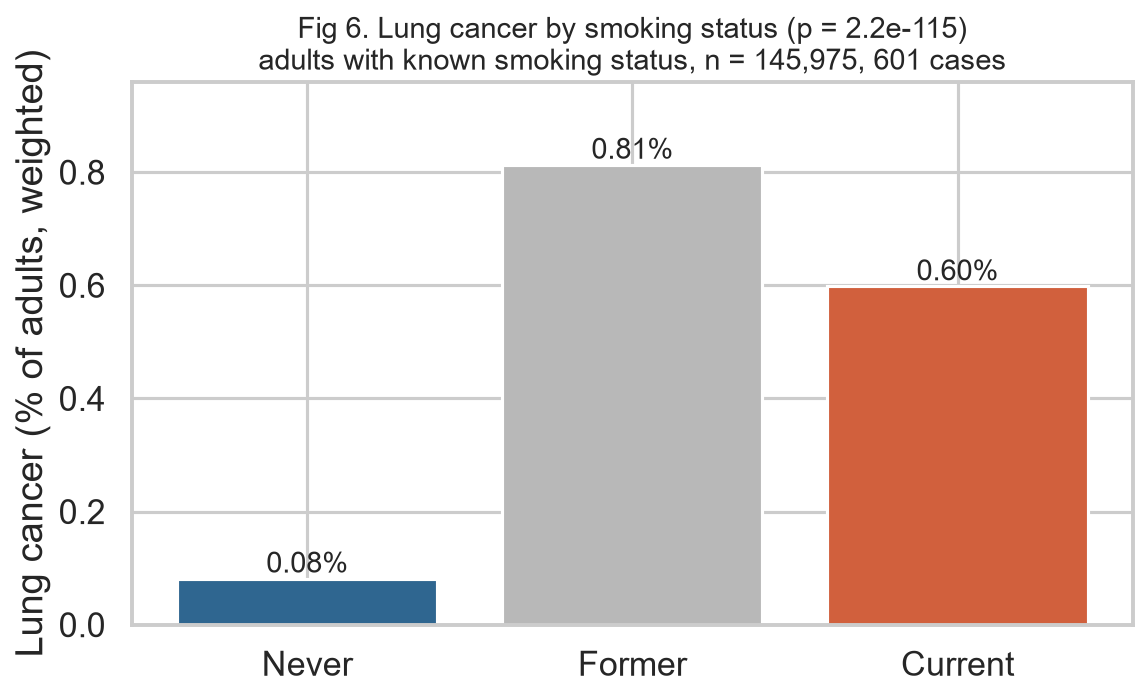


5. RQ1: IS THE SMOKING EFFECT JUST AGE? Smoking odds ratio inside each age group (CMH)
                                   group  adults  cases_ever_smokers  cases_never_smokers  odds_ratio  ci_low  ci_high
                                   18-44   53022                10.0                  3.0        7.73    2.31    25.92
                                   45-54   20987                11.0                 10.0        1.88    0.82     4.35
                                   55-64   26358                96.0                 15.0        8.18    4.78    13.99
                                   65-74   25842               187.0                 27.0        7.86    5.27    11.74
                                     75+   19455               189.0                 52.0        4.37    3.22     5.94
                     Crude (age ignored)  145664                 NaN                  NaN        7.64    6.20     9.41
Mantel-Haenszel (adjusted for age group)  145664                 NaN           

,group,adults,cases_ever_smokers,cases_never_smokers,odds_ratio,ci_low,ci_high
0,18-44,53022,10.0,3.0,7.731131,2.305663,25.923300
1,45-54,20987,11.0,10.0,1.882634,0.815128,4.348165
2,55-64,26358,96.0,15.0,8.177699,4.780384,13.989412
3,65-74,25842,187.0,27.0,7.864268,5.266408,11.743624
4,75+,19455,189.0,52.0,4.373097,3.217052,5.944566
5,Crude (age ignored),145664,NaN,NaN,7.636525,6.196949,9.410519
6,Mantel-Haenszel (adjusted for age group),145664,NaN,NaN,5.791232,4.691421,7.148873


In [13]:
rates = eda.smoking(df)
show("fig06_smoking_vs_lung_cancer", 550)
sup.smoking_by_age(df)

Among the 145,975 adults with a known smoking status, ever-smokers have 7.7 times the odds of a lung-cancer
history (95% CI 6.2–9.4). Former smokers have a higher weighted rate (0.81%) than current smokers (0.60%), most
likely because people quit after their diagnosis (reverse causation) and because former smokers are older.
Cramér's V is only 0.06 because the outcome is rare, which is why the odds ratio is the effect size we report.
Compared within the same age group (Mantel–Haenszel over five age groups), the odds ratio falls from 7.6 to 5.8:
part of the crude effect was age, but a strong association remains. Its size differs between age groups
(Breslow–Day p = 0.005): about 8 from 55 to 74, 4.4 at 75+, and not significant at 45–54.

### 4.2 RQ2a — age, and age × smoking


3. AGE vs LUNG CANCER  (RQ2a)
Subset: adults with known age, n = 149,575 (618 cases), unweighted; rate by age group weighted.
Median age: lung cancer 72 vs no lung cancer 54
Normality check (Shapiro-Wilk on 5,000 ages): p = 5.71e-33 -> age is not normal
Mann-Whitney U test
  H0: people with and without lung cancer have the same age distribution
  Why not a t-test: age is not normal and the groups are very unequal in size (618 vs 148,957)
  Result: U = 73,126,291, p = 3.09e-141, effect size (rank-biserial r) = 0.59
  Robustness check - Welch t-test (valid for large samples): t = 44.9, p = 4.59e-199
  -> both tests agree, so the conclusion does not depend on the choice of test.


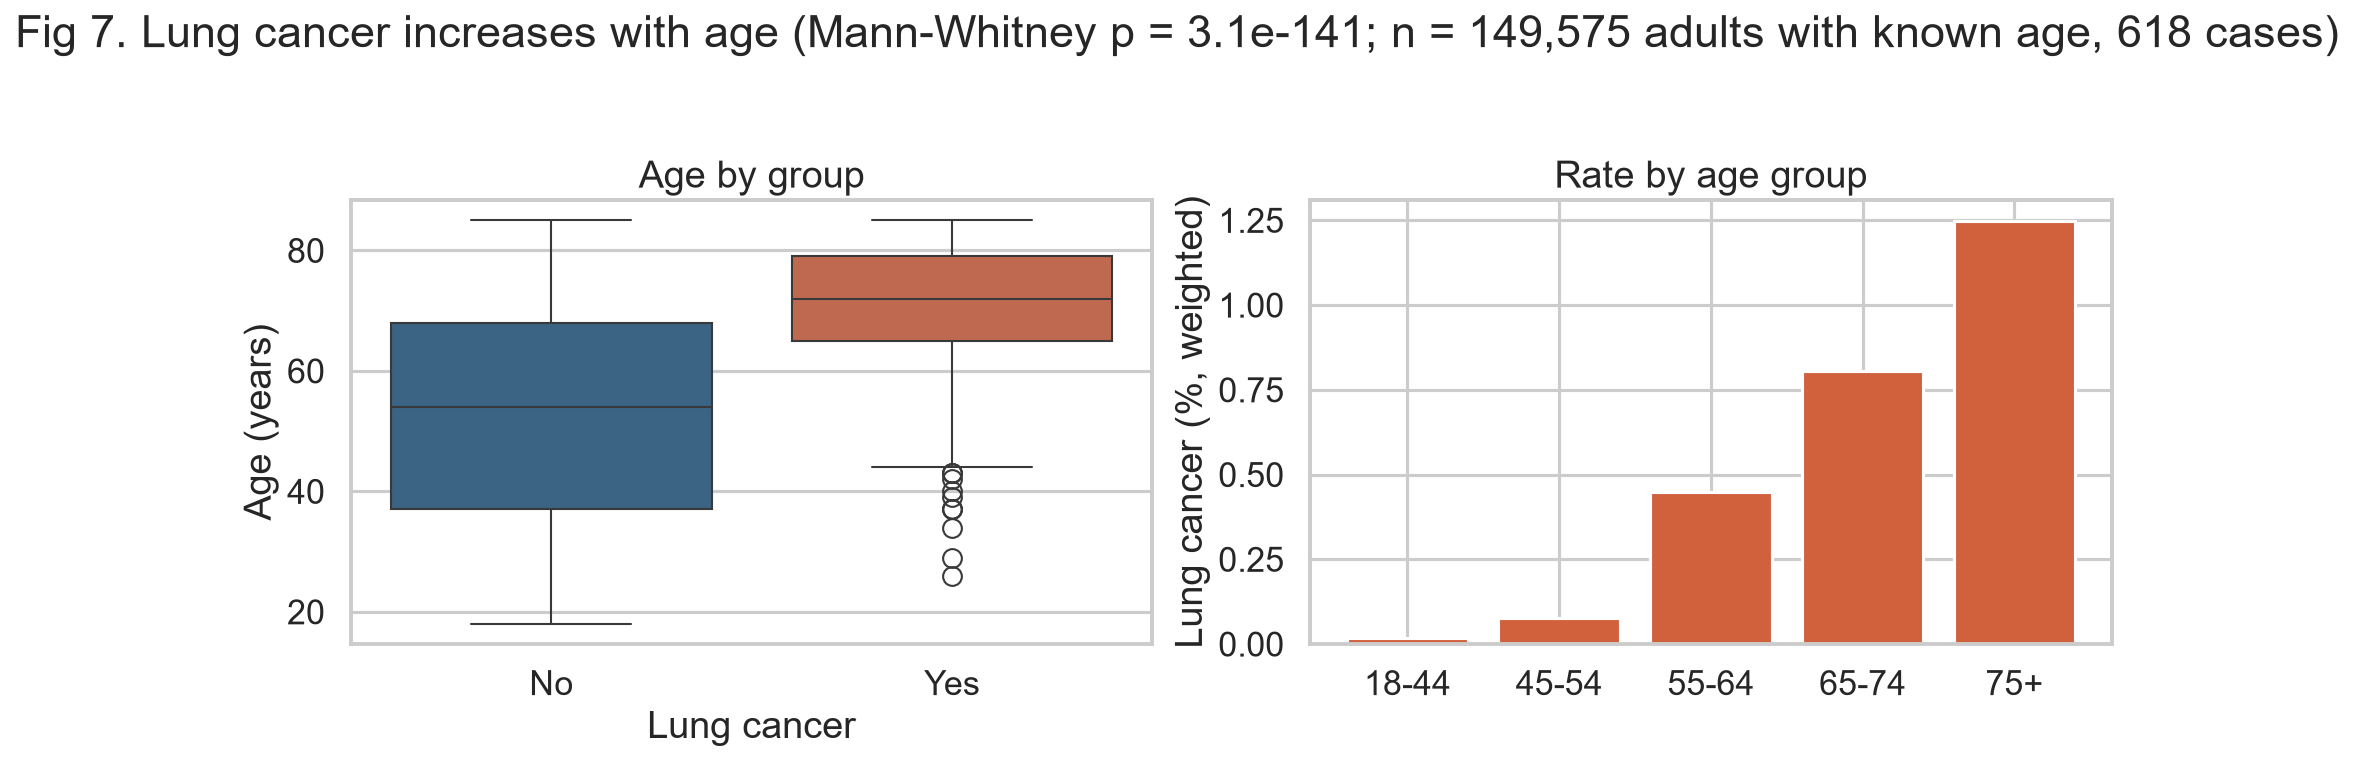

In [14]:
ag = eda.age(df, sw)
show("fig07_age_vs_lung_cancer", 850)

Adults with lung cancer are much older (median 72 vs 54; Mann–Whitney p = 3.1e-141, rank-biserial r = 0.59): a
random case is older than a random non-case about 79.5% of the time. The weighted rate rises steadily from 0.02%
at 18–44 to 1.25% at 75+.


5. SMOKING x AGE  (RQ2a: age combined with smoking status)
Survey-weighted lung cancer rate (%); adults with known age group and smoking status, n = 145,664 (600 cases):
smoking_status  Never  Former  Current
age_group                             
18-44            0.00    0.04     0.09
45-54            0.06    0.08     0.16
55-64            0.13    0.77     1.14
65-74            0.16    1.48     1.75
75+              0.48    2.15     2.37
Reading: the smoking gap opens after 55 -> age and smoking act together; this supports the
screening_age_smoker feature (age 50-80 AND ever smoked).


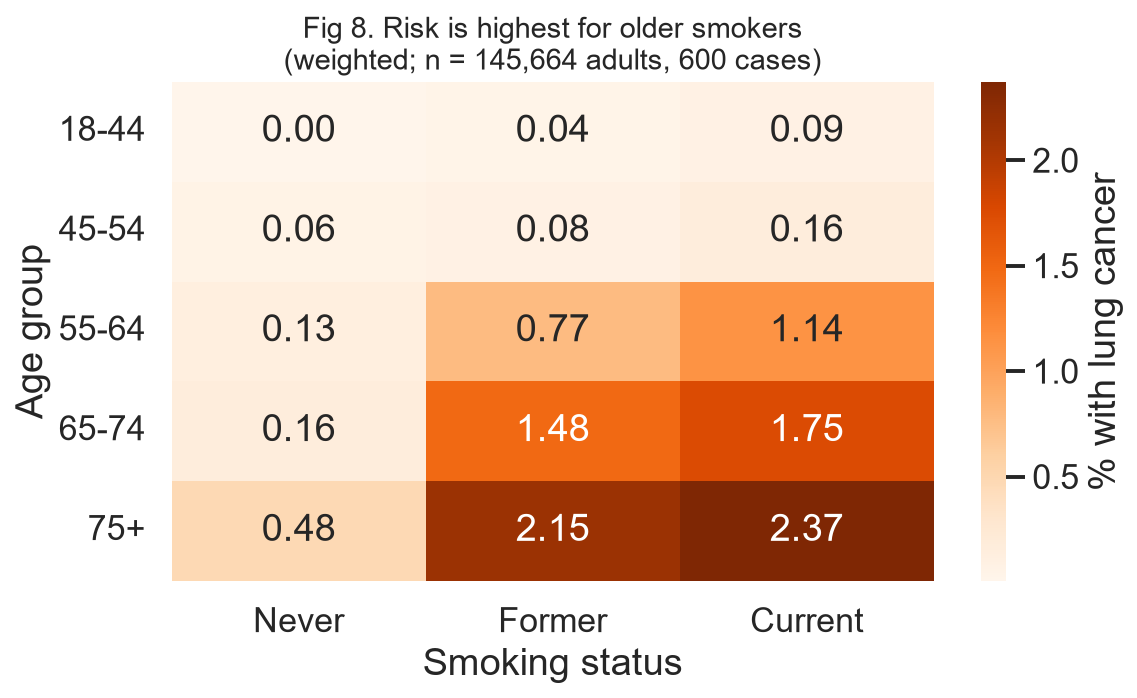

In [15]:
inter = eda.age_x_smoking(df)
show("fig08_age_x_smoking", 550)

Never-smokers stay below 0.5% even at 75+, while ever-smokers reach 2.15–2.37%: age and smoking act together,
which is the logic of `screening_age_smoker`.

### 4.3 RQ2b — chronic conditions and e-cigarettes, and is COPD only smoking?


4. COPD, OTHER CONDITIONS AND E-CIGARETTES  (RQ2b)
Each row: adults with that condition known (adults, cases); rates and odds ratios unweighted.
      condition  adults  cases  rate_if_yes_%  rate_if_no_%  odds_ratio  ci_low  ci_high        p  cramers_v  min_expected
           copd  149826    618          3.412         0.233      15.103  12.877   17.715 < 1e-300      0.114        34.813
  heart_disease  149597    614          1.532         0.338       4.599   3.803    5.561 5.64e-66      0.045        37.239
   hypertension  149766    619          0.738         0.226       3.272   2.772    3.861 1.26e-49      0.038       226.395
       diabetes  149860    619          0.815         0.365       2.252   1.856    2.732 6.74e-17      0.022        66.353
         asthma  149864    618          0.557         0.389       1.438   1.175    1.760 5.72e-04      0.009        85.935
ever_ecigarette  146076    602          0.447         0.405       1.108   0.898    1.368 3.87e-01      0.002        

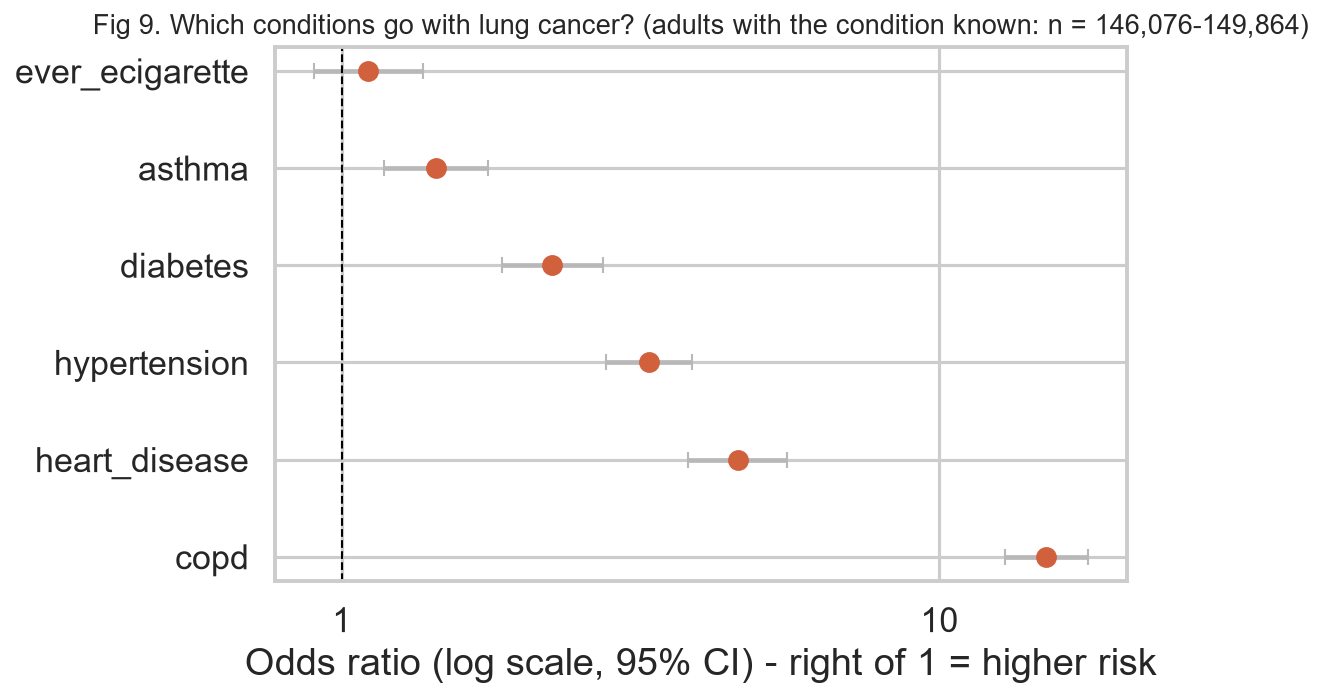

In [16]:
cond = eda.conditions(df)
show("fig09_odds_ratios_conditions", 600)

COPD is the strongest signal (odds ratio 15.1, among the 149,826 adults with a known COPD answer), followed by
heart disease (4.6), hypertension (3.3) and diabetes (2.3); asthma is significant but negligible and e-cigarette
use shows nothing. These odds ratios are crude: part of each one is age.


4b. IS THE COPD LINK ONLY DUE TO SMOKING?  (confounding check, RQ2b)
Problem: smokers get COPD more often AND lung cancer more often, so smoking could create a
COPD-lung cancer link on its own (confounding). Solution: compare COPD vs no COPD WITHIN each
smoking group, then pool the groups with the Cochran-Mantel-Haenszel (CMH) test.
Subset: adults with known COPD and smoking status, n = 145,897 (600 cases), unweighted.
                                 group      n  cases  odds_ratio  ci_low  ci_high
                         Never smokers  90901    107        8.45    4.99    14.31
                        Former smokers  37424    366        9.78    7.94    12.03
                       Current smokers  17572    127        8.38    5.88    11.93
               Crude (smoking ignored) 145897    600       14.77   12.56    17.37
Mantel-Haenszel (adjusted for smoking) 145897    600        9.28    7.81    11.01
CMH test  H0: no COPD-lung cancer link once smoking is held fixed
  Result: chi2 = 9

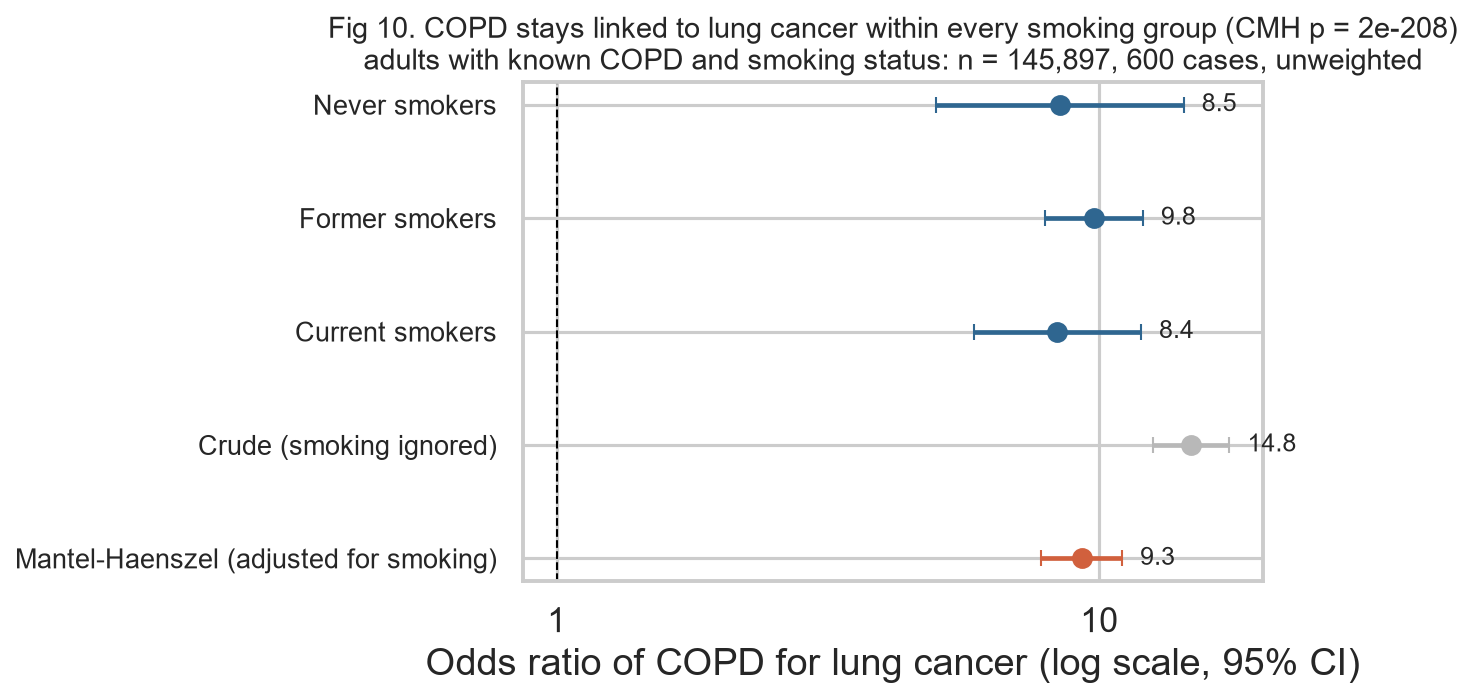


6. RQ2b: COPD ADJUSTED FOR SMOKING, THEN FOR SMOKING x AGE GROUP
Adults with known COPD, smoking status and age: 145,587 (599 cases)
                adjustment  odds_ratio  ci_low  ci_high  strata
              none (crude)       14.71   12.50    17.30       1
            smoking status        9.24    7.78    10.98       3
smoking status x age group        5.73    4.82     6.82      15
CMH test with smoking x age strata: chi2 = 501.9, p = 3.7e-111


,adjustment,odds_ratio,ci_low,ci_high,strata
0,none (crude),14.706121,12.504681,17.295122,1
1,smoking status,9.243090,7.784183,10.975424,3
2,smoking status x age group,5.730403,4.817729,6.815975,15


In [17]:
strata = eda.copd_confounding(df)
show("fig10_copd_stratified_by_smoking", 650)
sup.copd_adjusted(df)

Among the 145,897 adults with known COPD and smoking status, the crude odds ratio of 14.8 falls to 9.3 once
smoking is held fixed, with similar values in never, former and current smokers (Breslow–Day p = 0.69); adding
age group lowers it to 5.7. COPD therefore stays strongly associated with lung cancer beyond smoking and age —
still an association, not a cause.

### 4.4 RQ2c — socio-demographic and health factors


4c. SOCIO-DEMOGRAPHIC AND HEALTH FACTORS  (RQ2c)
Note: race groups AIAN, 'AIAN and other' and 'Other or multiple' are merged for the test
(expected counts below 5 otherwise, which makes the chi-square approximation unreliable).

Sex  -  H0: sex and lung cancer are not related
  Adults with sex known: n = 149,912 (619 cases); rates survey-weighted, test unweighted
  Weighted lung cancer rate (%): Female 0.32, Male 0.30
  chi2(1) = 2.0, p = 1.56e-01, Cramer's V = 0.004, smallest expected count = 283.1

Race / ethnicity  -  H0: race_ethnicity and lung cancer are not related
  Adults with race_ethnicity known: n = 149,928 (619 cases); rates survey-weighted, test unweighted
  Weighted lung cancer rate (%): White 0.39, Black 0.22, Hispanic 0.10, Asian 0.22, AIAN / other / multiple 0.28
  chi2(4) = 70.7, p = 1.63e-14, Cramer's V = 0.022, smallest expected count = 15.5

Education  -  H0: education and lung cancer are not related
  Adults with education known: n = 149,168 (612 cases); rates su

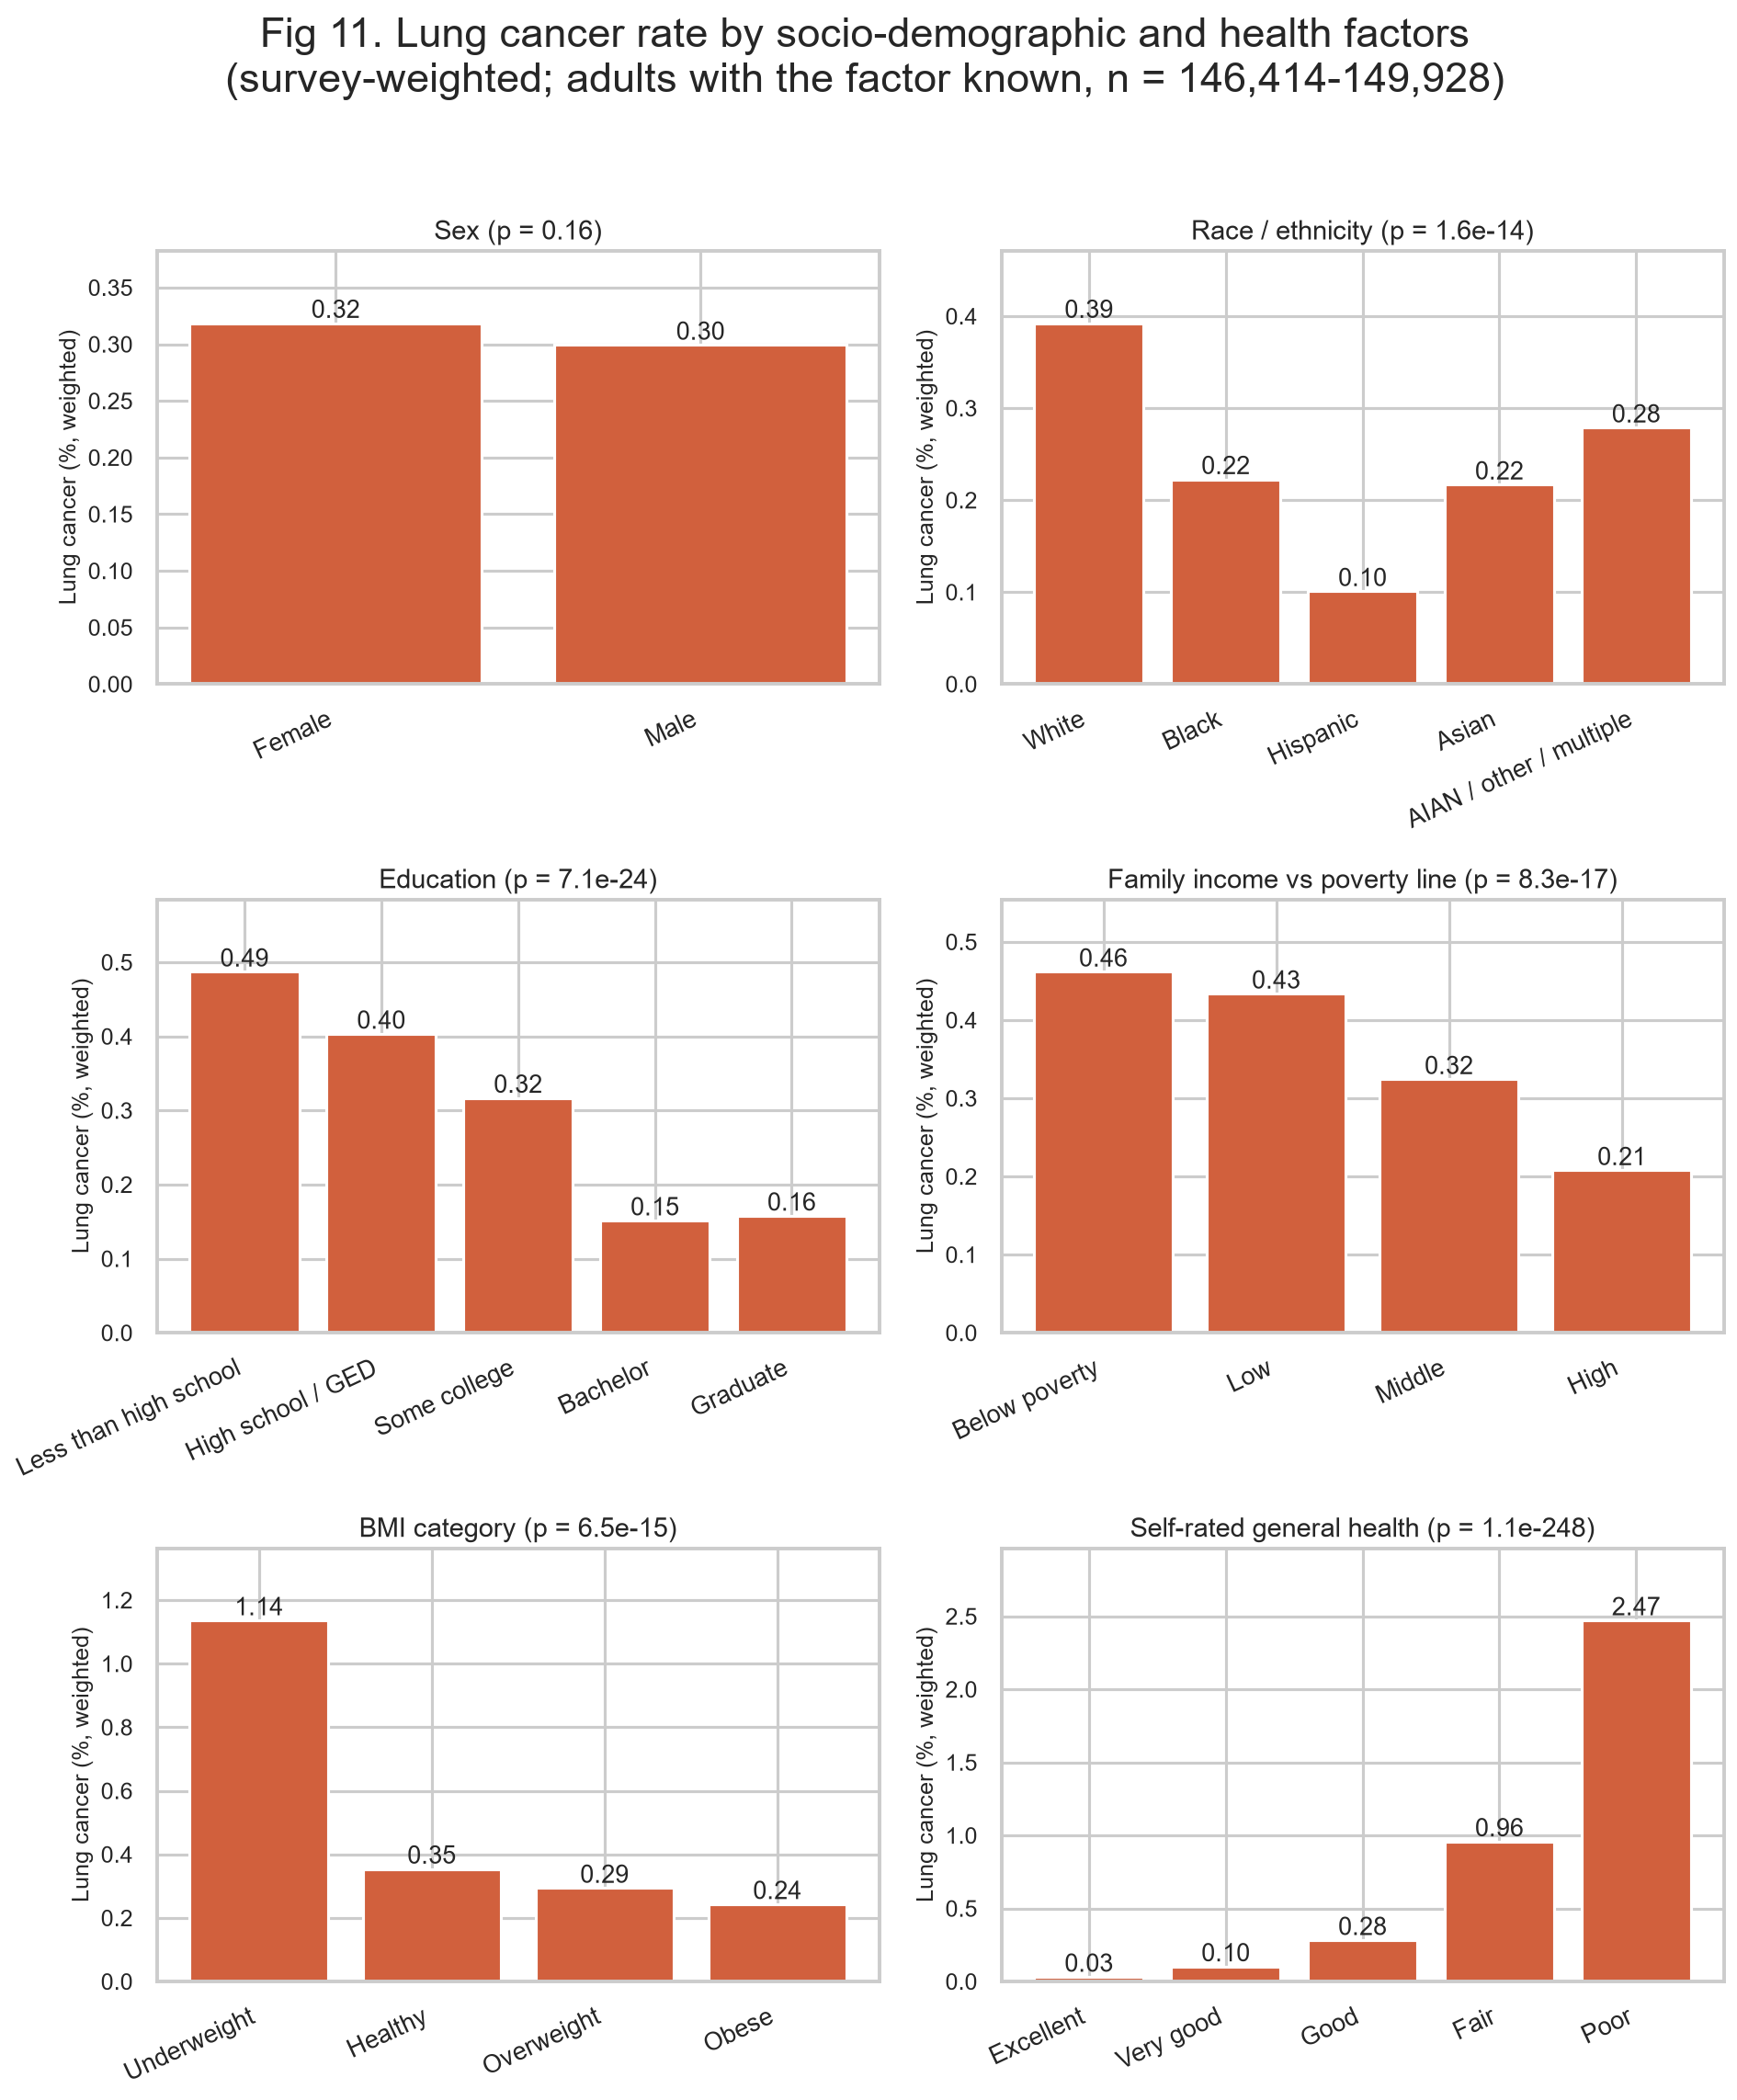

In [18]:
demo = eda.demographics(df)
show("fig11_demographics_vs_lung_cancer", 750)

Sex is not associated with lung cancer (p = 0.16); the other five factors are (chi-square, all Cramér's V small).
Read from the weighted rates across the ordered levels (not tested as a trend), the rate falls from 0.49% to about
0.15% with education and from 0.46% to 0.21% with income – but smoking follows the same pattern, so part of it is
smoking again – and climbs from 0.03% ("excellent" health) to 2.47% ("poor"). Underweight adults and those in poor self-rated
health have the highest rates, most likely because cancer causes weight loss and poor health (reverse causation).

### 4.5 Correlation and association matrices


6. CORRELATIONS (Spearman)
Data: all 149,928 adults (619 cases), unweighted; each pair uses the adults with
both values known (n = 145,664 to 149,928).
Strongest pairs: hypertension-comorbidity_count 0.79; diabetes-comorbidity_count 0.49; asthma-comorbidity_count 0.45; age-hypertension 0.44; smoking_rate-lung_cancer_incidence 0.43; age-comorbidity_count 0.41
Why Spearman and not Pearson: most columns are 0/1 or ordered, and age is not normal; Spearman
uses ranks, so it only assumes a monotonic (always up or always down) relationship.


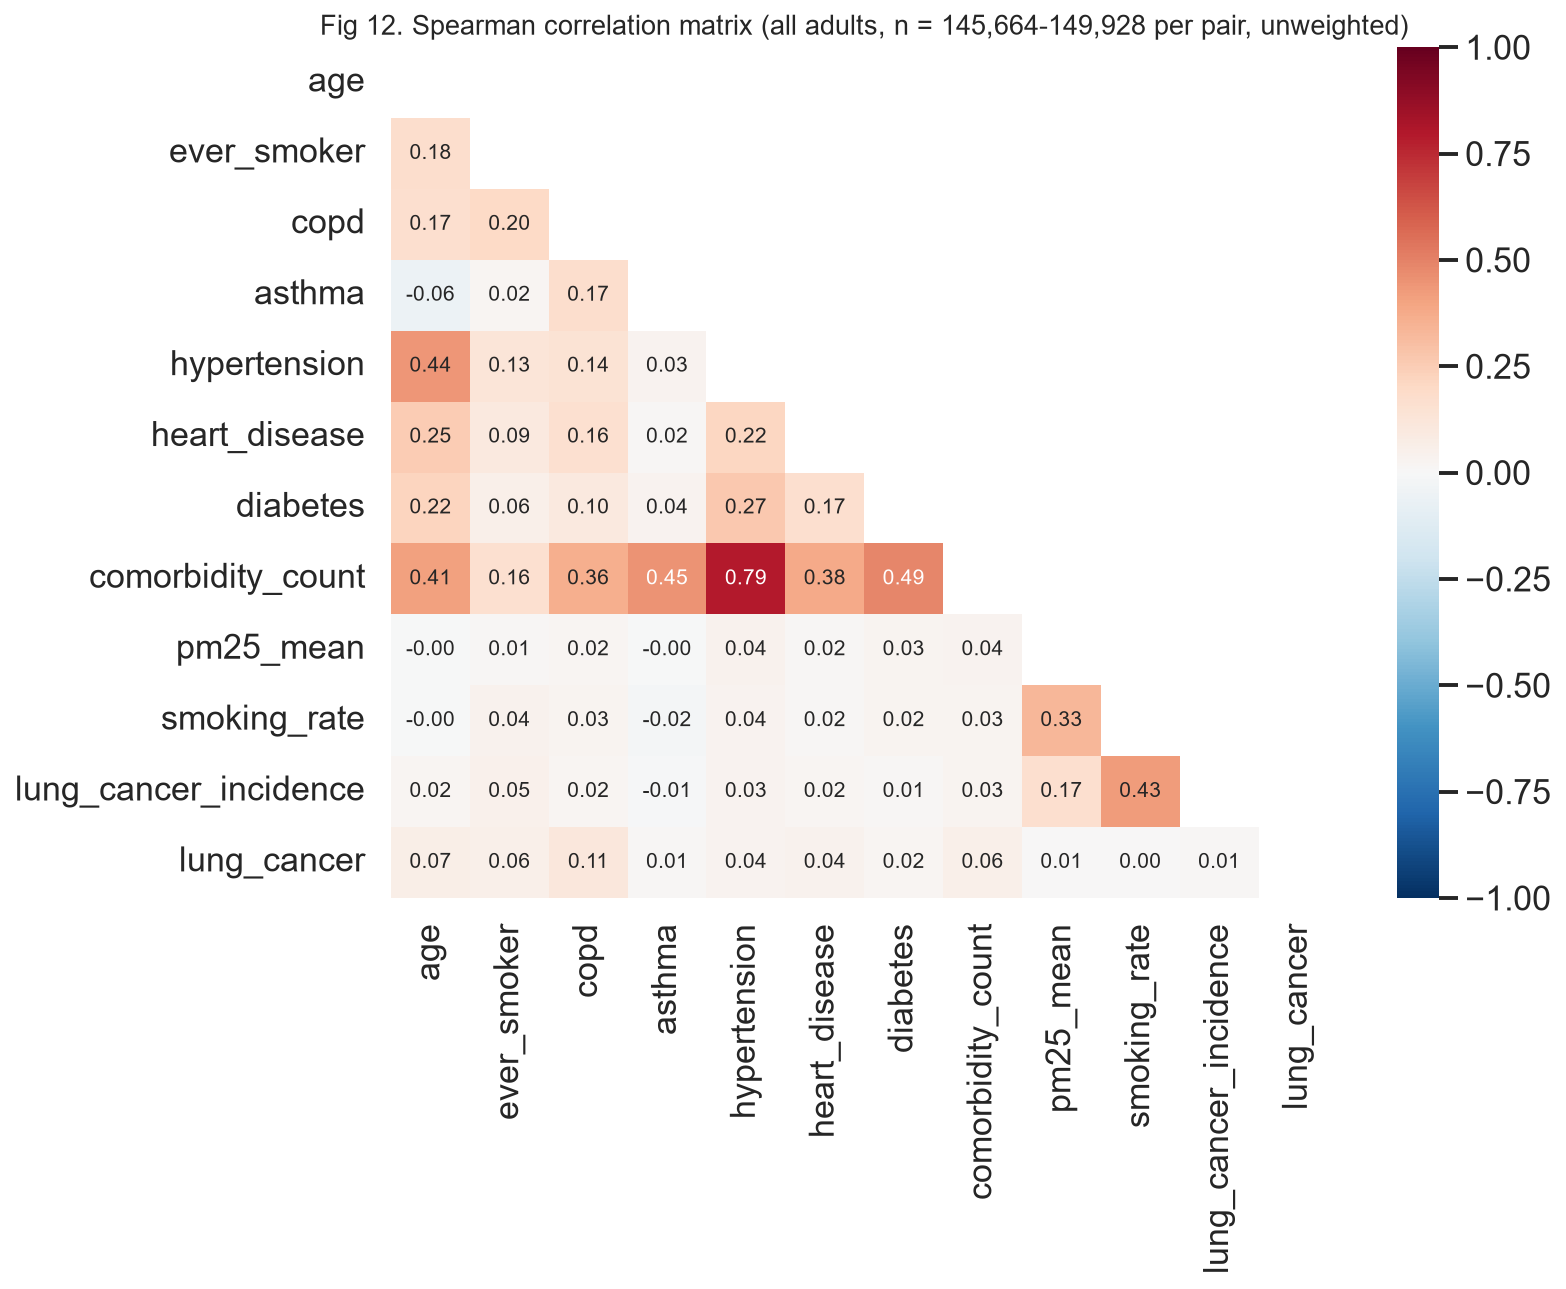

In [19]:
corr = eda.correlations(df)
show("fig12_correlation_heatmap", 650)

On the numeric and 0/1 variables (all adults, pairwise complete), the only pair above 0.5 is hypertension with
comorbidity count (0.79), and it is high by construction: the count is the sum of the five condition flags.
Every correlation with the target is small (COPD 0.11 at most).


6b. ASSOCIATION MATRIX OF ALL ANALYSIS VARIABLES (Fig 12b)
24 variables = the 26 columns of the clean file minus person_id and survey_weight (CANEV_A is not in it).
Numeric: age, comorbidity_count, pm25_mean, smoking_rate, lung_cancer_incidence. Every other variable is categorical (0/1 flags, ordered groups, year).
Methods: Cramer's V for categorical-categorical, correlation ratio eta for categorical-numeric,
|Spearman| for numeric-numeric. All three run from 0 (no association) to 1 (one determines the other).
Data: all 149,928 adults, unweighted; each pair uses the adults with both values known (n = 142,511 to 149,928).
Strongest pairs: smoking_status-ever_smoker 1.00 (Cramer's V); region-lung_cancer_incidence 0.98 (eta); age-age_group 0.96 (eta); region-smoking_rate 0.73 (eta); hypertension-comorbidity_count 0.73 (eta); region-pm25_mean 0.71 (eta); smoking_status-screening_age_smoker 0.69 (Cramer's V); ever_smoker-screening_age_smoker 0.69 (Cramer's V)
With the target: copd 0.114; g

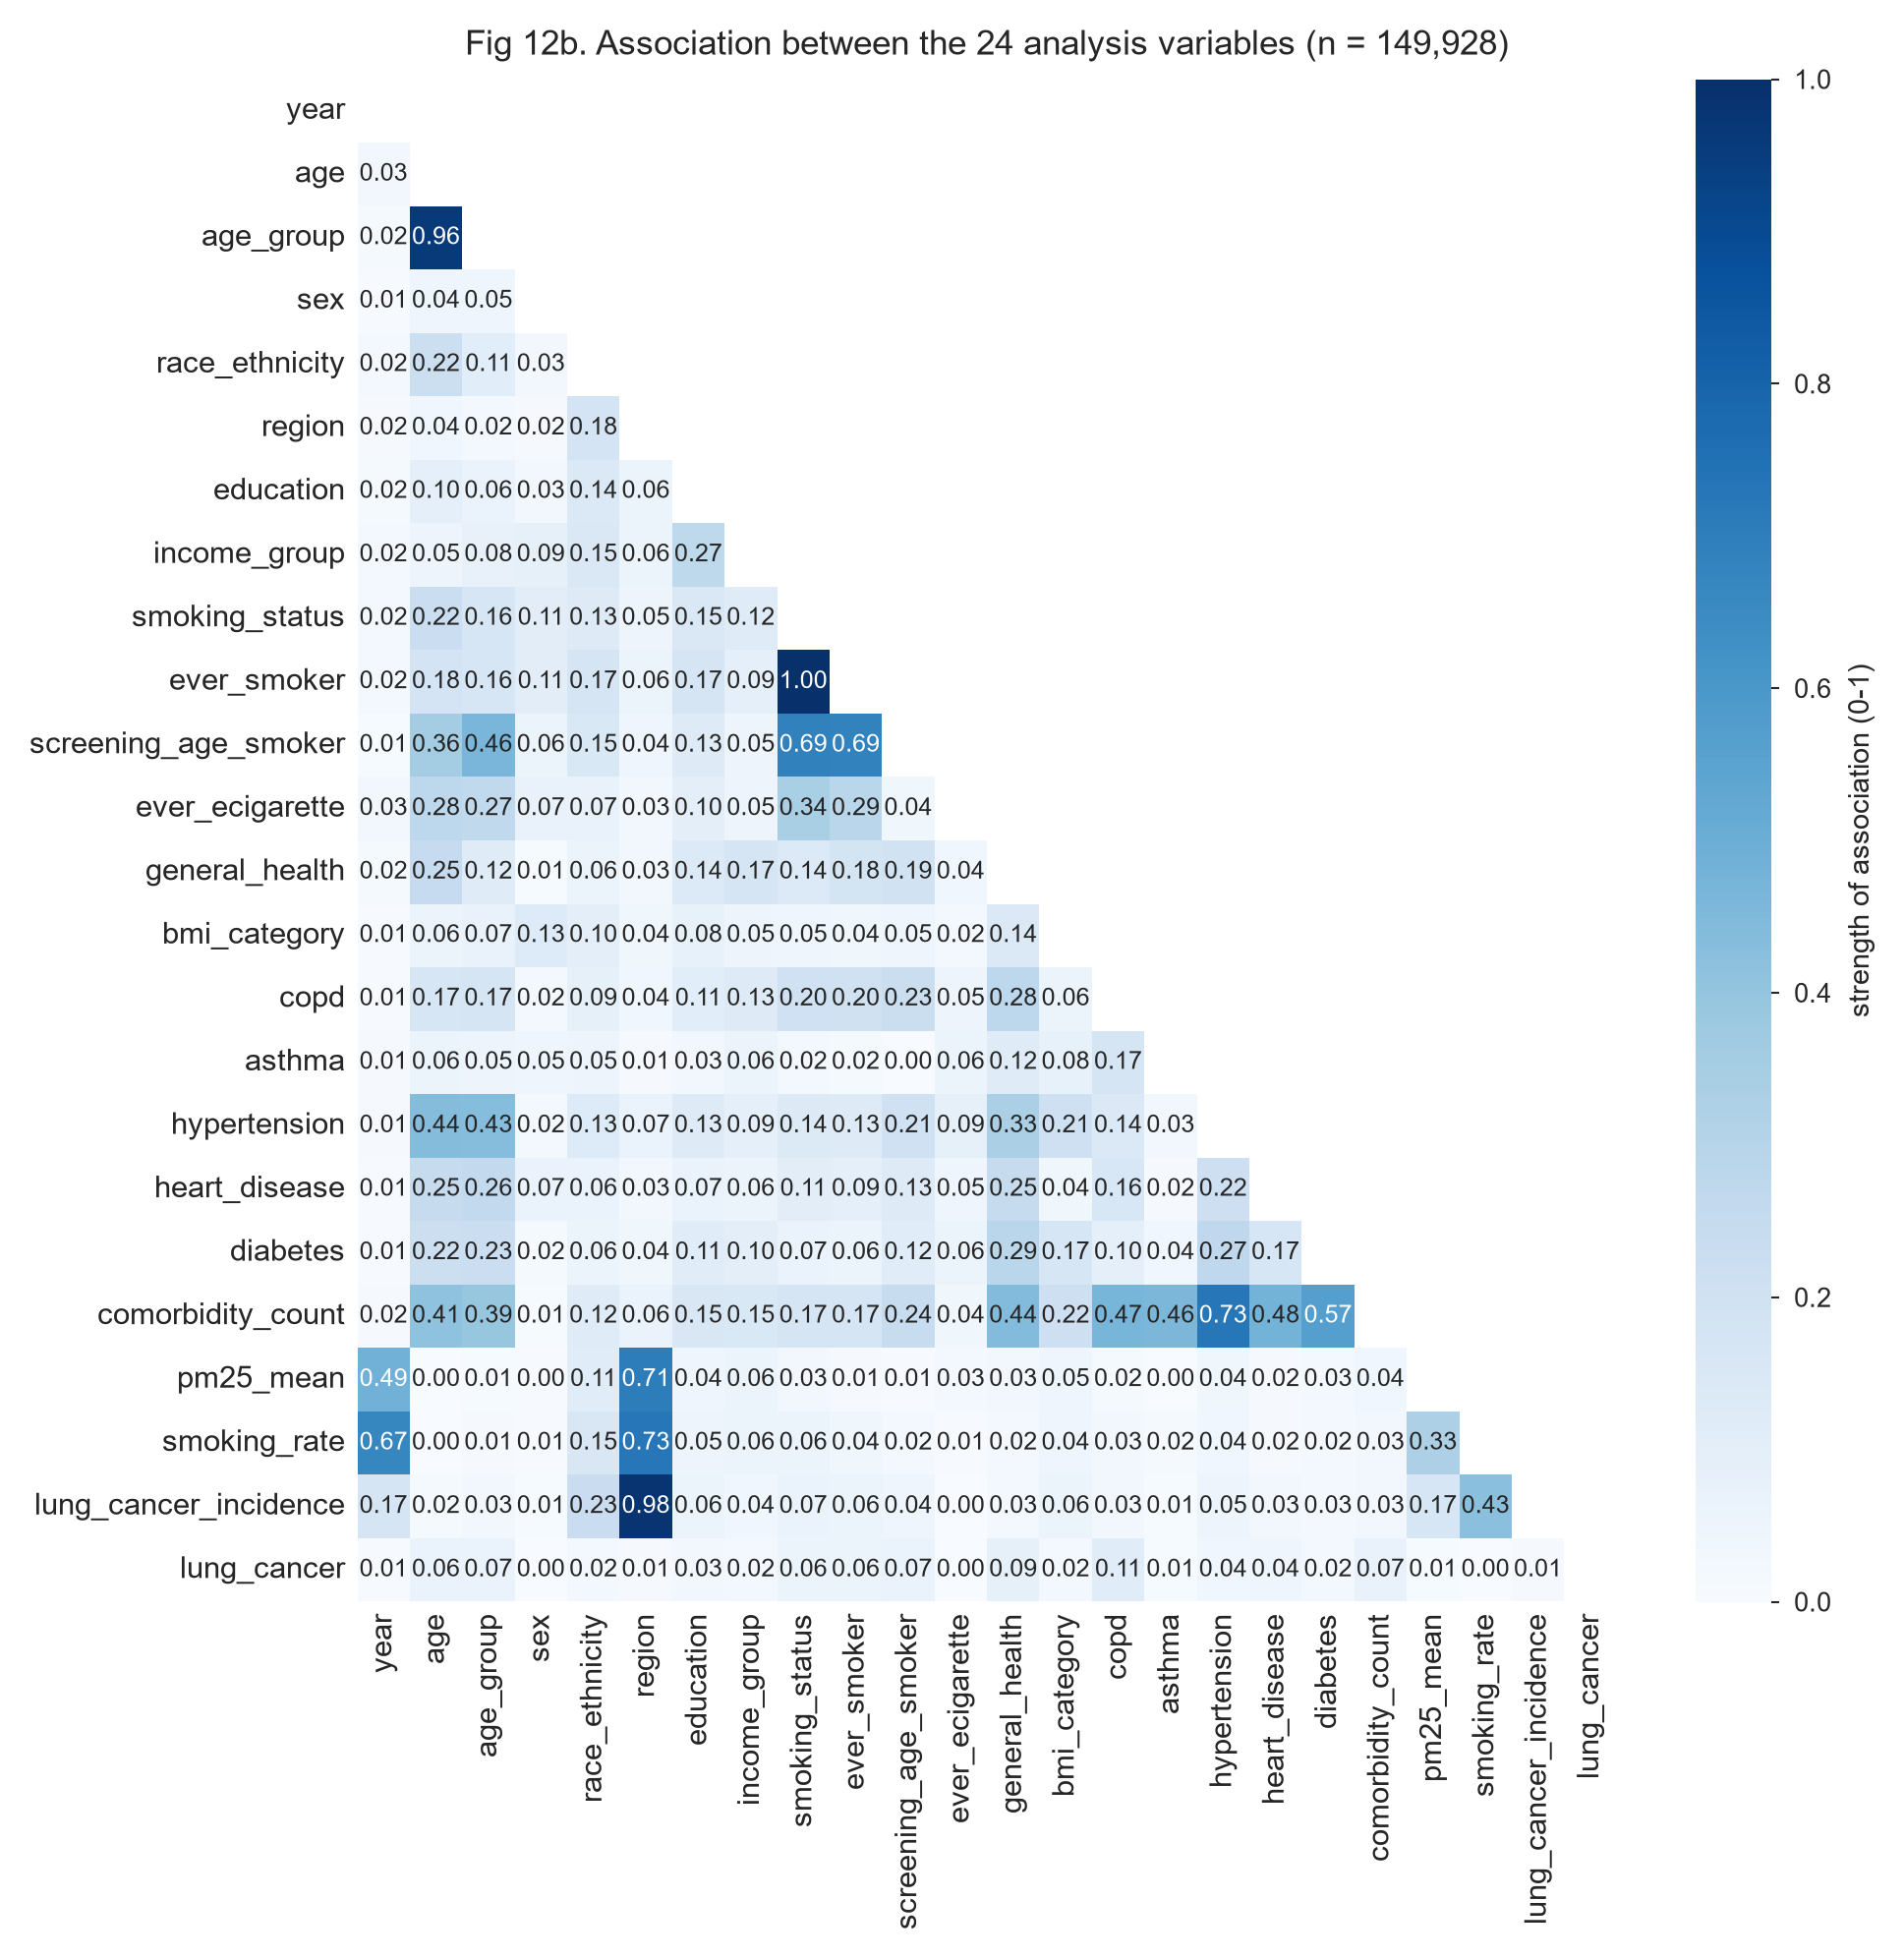

In [20]:
assoc, var_pairs = eda.association_matrix(df)
show("fig12b_association_matrix", 900)

Fig 12b covers all 24 analysis variables, including the categorical ones that Fig 12 could not show, with
Cramér's V, the correlation ratio η or |Spearman| depending on the variable types. The strong cells are all
built-from relations — smoking status vs ever-smoker (1.00), region vs registry incidence (0.98), age vs age
group (0.96), region and year vs the regional columns — not independent measurements that duplicate each other.


6c. CORRELATIONS BETWEEN THE FINAL MODEL FEATURES (Fig 12c, training rows)
Data: 38 final features + the target on the 119,942 training rows (495 cases), unweighted; Spearman; no missing values.
Feature pairs with |r| >= 0.3: 9; with |r| > 0.5: 2
Largest: ever_ecigarette_unknown-screening_age_smoker_unknown +0.93; smoking_status_Former-screening_age_smoker +0.55; bmi_category_Overweight-bmi_category_Obese -0.49; general_health_Very good-general_health_Good -0.46; hypertension-age +0.44; lung_cancer_incidence-smoking_rate +0.43


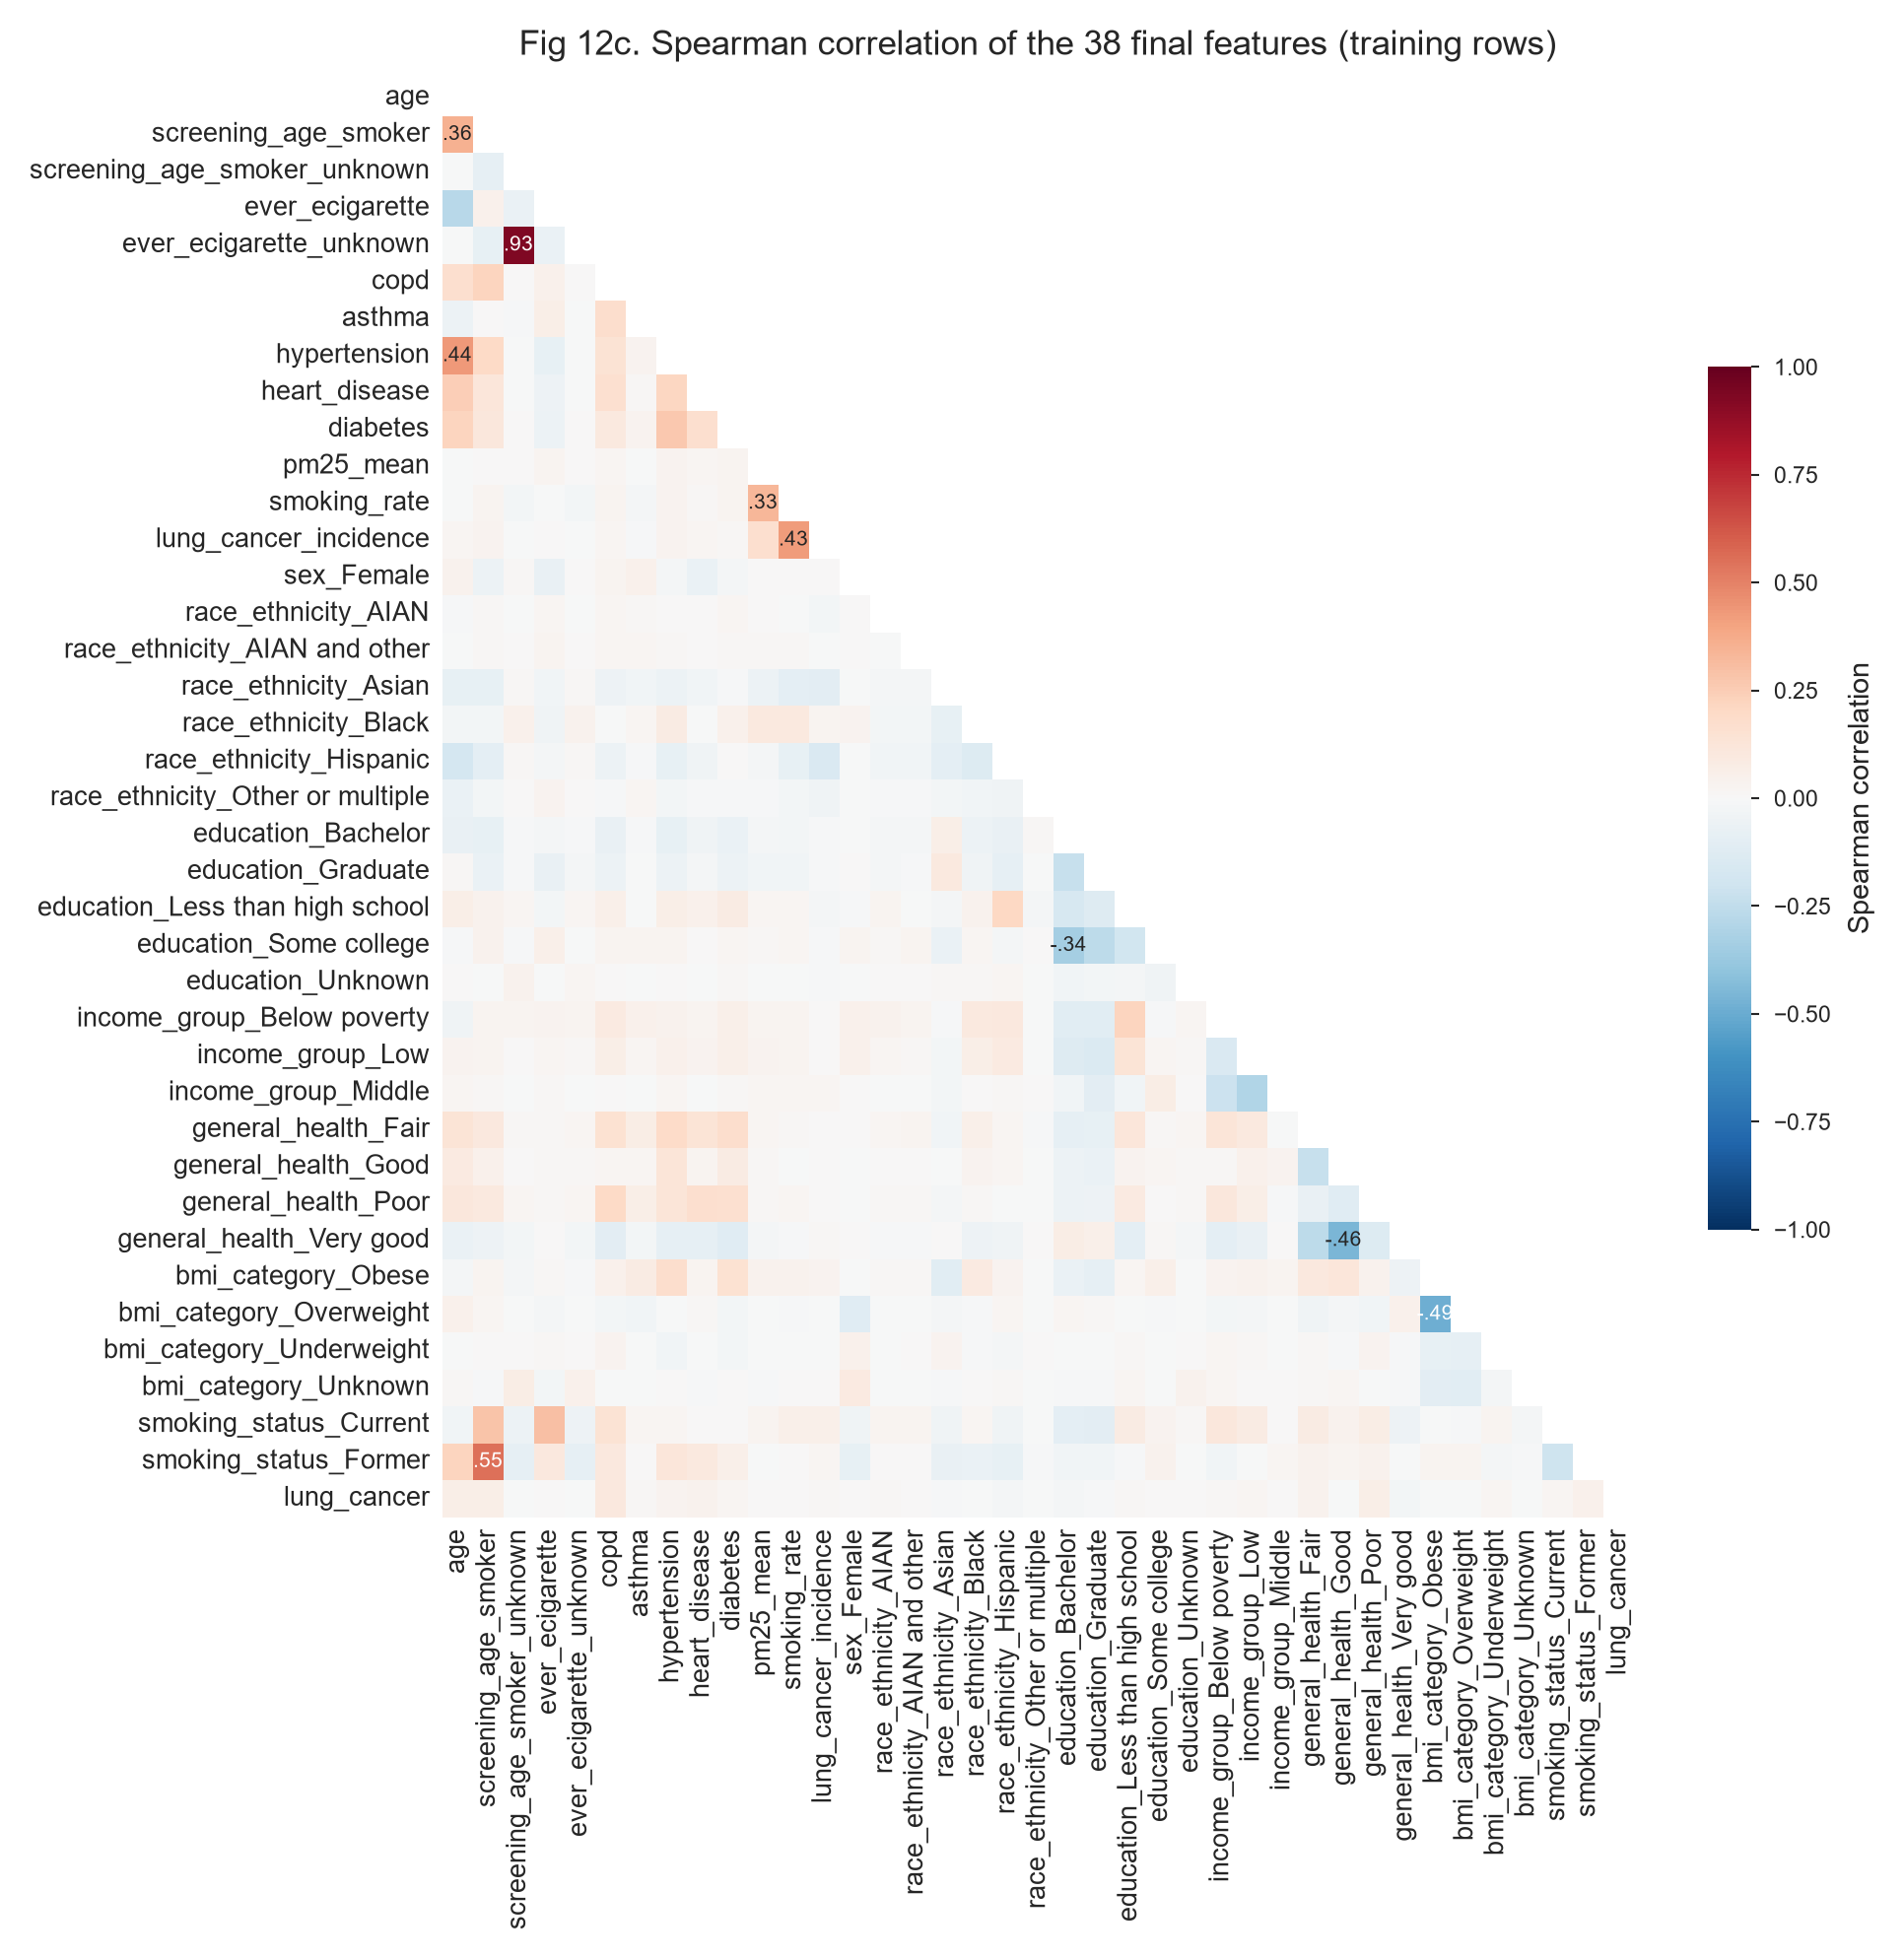

In [21]:
feat_corr = eda.feature_correlations(mr)
show("fig12c_feature_correlation", 950)

Among the 38 final features (training rows), only two pairs exceed 0.5: the two "unknown" flags (0.93, both mark
adults who skipped the smoking questions) and `screening_age_smoker` with former smoking (0.55, the screening
flag is built from smoking status). Both are kept on purpose and have VIFs below 10.

In [22]:
pairs = eda.high_correlation_pairs(var_pairs, feat_corr, int((mr.split == "train").sum()))
bound = eda.target_correlation_bound(df)


Pairs above 0.5 (results/tables/high_correlation_pairs.csv):
                           matrix                        var_a                   var_b    measure  value         type
  Fig 12b (variables, all adults)                         year            smoking_rate        eta   0.67   built-from
  Fig 12b (variables, all adults)                          age               age_group        eta   0.96   built-from
  Fig 12b (variables, all adults)                       region               pm25_mean        eta   0.71   built-from
  Fig 12b (variables, all adults)                       region            smoking_rate        eta   0.73   built-from
  Fig 12b (variables, all adults)                       region   lung_cancer_incidence        eta   0.98   built-from
  Fig 12b (variables, all adults)               smoking_status             ever_smoker Cramer's V   1.00   built-from
  Fig 12b (variables, all adults)               smoking_status    screening_age_smoker Cramer's V   0.69   built

All 12 pairs above 0.5 are built-from (11) or same-concept (1); none is a genuine association between two
separately measured variables. Correlations with the target are small for a structural reason: with a 0.41%
outcome, a 0/1 feature with 5.6% prevalence (COPD) can reach at most φ = 0.26, and COPD's 0.11 is 43% of that
maximum — with an odds ratio of 15.1. Correlations with a rare target must be read alongside odds ratios.

### 4.6 RQ3 — regional context


7. REGIONAL DATA  (RQ3) + cross-source check
Cross-source validation: does the NHIS self-reported rate follow the official cancer-registry rate?
Unit: 20 region-years (4 regions x 5 years). NHIS rate = survey-weighted rate of the adults in that
region-year: 4,574-11,646 adults each (149,928 adults and 619 cases in total).
  Spearman rho (20 region-years) = 0.79, p = 3.5e-05
  (Not the same measure: NHIS = people EVER diagnosed; registry = NEW cases per year.)
  pm25_mean              vs NHIS rate: rho = -0.12, p = 0.63
  smoking_rate           vs NHIS rate: rho = 0.09, p = 0.71
  lung_cancer_incidence  vs NHIS rate: rho = 0.79, p = 3.5e-05
Note: only 20 region-years -> low power; regional columns give context, not personal detail.
Section 9 adds that, as features, the three regional columns carry one shared signal (which region-year),
so they cannot separate the effect of pollution, regional smoking and registry incidence.
Limits: registry rates are crude (not age-adjusted), state val

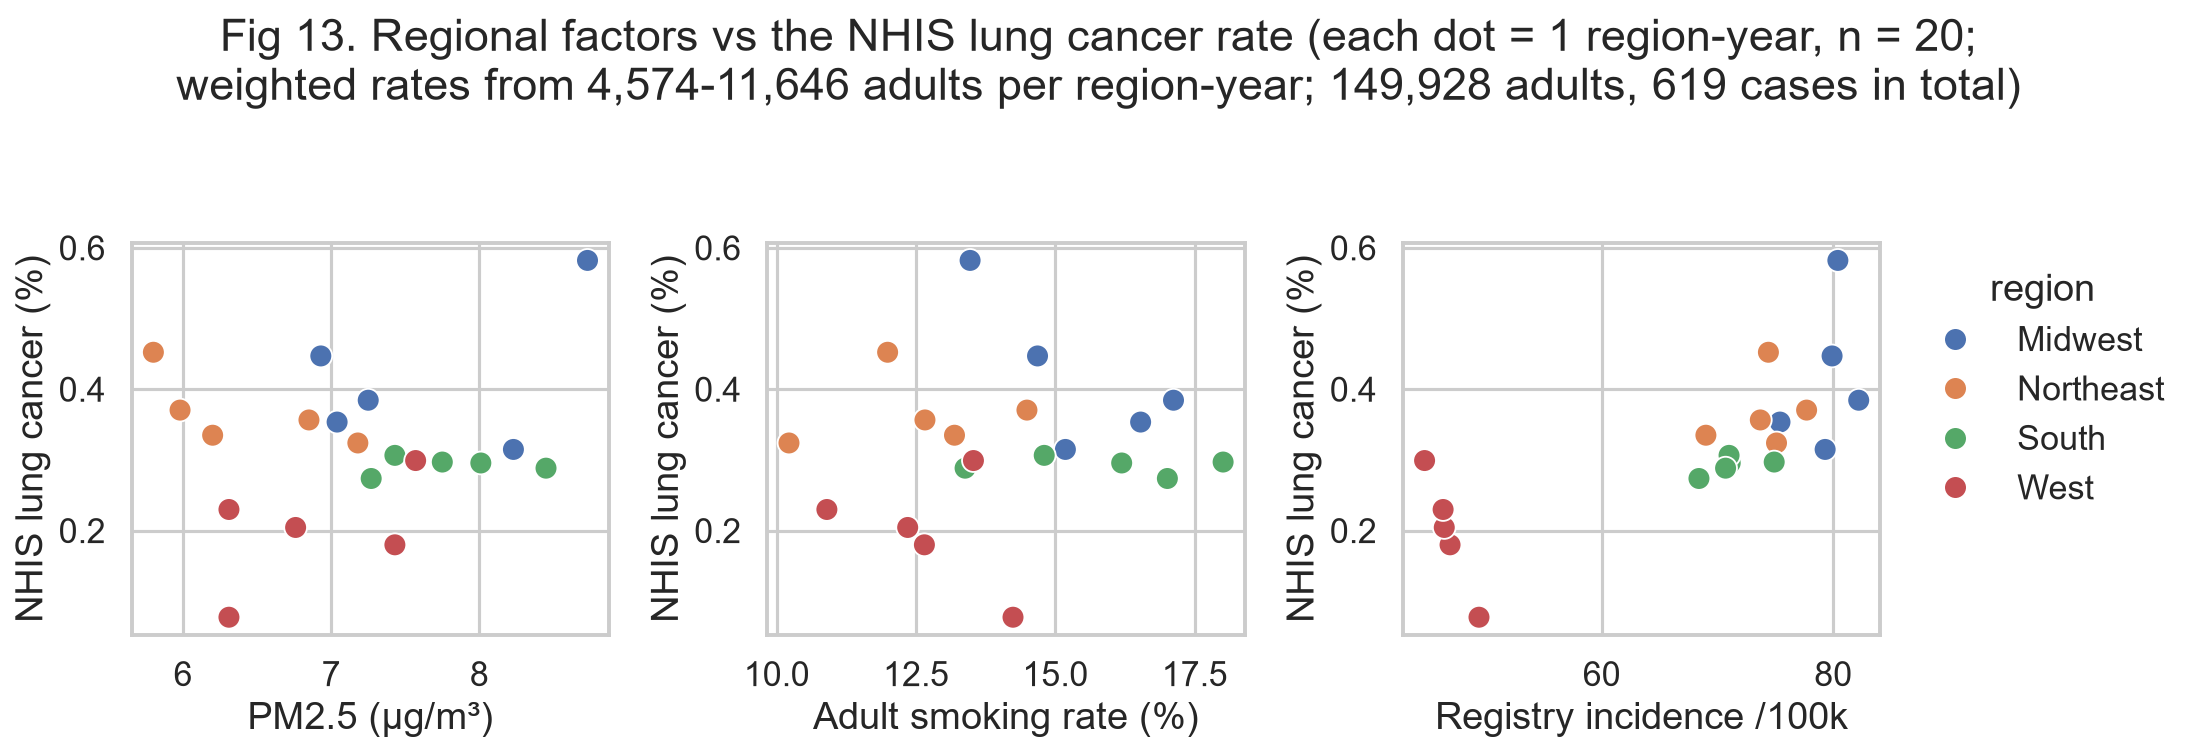


7. RQ3: BETWEEN-REGION AND WITHIN-REGION CORRELATIONS
The 20 region-years are 4 regions x 5 years, so they are not 20 independent observations.
Region means over 2019-2023:
           nhis_rate_%  pm25_mean  smoking_rate  lung_cancer_incidence  pooled_weighted_rate_%  pooled_sample_rate_%
region                                                                                                              
Midwest          0.416      7.636        15.396                  79.44                   0.417                 0.526
Northeast        0.368      6.402        12.510                  73.98                   0.368                 0.469
South            0.292      7.782        15.878                  71.22                   0.292                 0.421
West             0.198      6.876        12.734                  46.74                   0.198                 0.263
     regional_measure  rho_all_20 p_all_20  rho_between_4_regions  rho_within_region p_within_region
            pm25_mean  

,regional_measure,rho_all_20,p_all_20,rho_between_4_regions,rho_within_region,p_within_region
0,pm25_mean,-0.115124,0.628874,0.0,0.031591,0.894815
1,smoking_rate,0.087218,0.714638,0.0,-0.347368,0.133449
2,lung_cancer_incidence,0.789474,0.000035,1.0,0.033083,0.889876


In [23]:
reg = eda.regional(df, ctx)
show("fig13_regional_factors", 950)
sup.regional_within_between(df)

Over 20 region-years the survey rate follows the registry incidence (ρ = 0.79, p = 3.5e-05), but this comes from
the differences between the 4 regions (the West is low on both, between-region ρ = 1.0) and not from year-to-year
changes (within-region ρ = 0.03), so it supports the target without validating it. PM2.5 and the regional smoking
rate show no association; their between-region ρ of exactly 0 is real — with n = 4, ρ only takes a few values.

### 4.7 All tests with Holm correction, and the survey-design check

In [24]:
tt = eda.multiple_testing()


8. ALL TESTS, CORRECTED FOR MULTIPLE TESTING (Holm)
                                                                   test research_question         p    p_holm  significant_after_correction
                             Smoking status vs lung cancer (chi-square)               RQ1 2.20e-115 3.09e-114                          True
                                      Age vs lung cancer (Mann-Whitney)              RQ2a 3.09e-141 4.64e-140                          True
                                       copd vs lung cancer (chi-square)              RQ2b  < 1e-300  < 1e-300                          True
                                     asthma vs lung cancer (chi-square)              RQ2b  5.72e-04  2.86e-03                          True
                               hypertension vs lung cancer (chi-square)              RQ2b  1.26e-49  1.51e-48                          True
                              heart_disease vs lung cancer (chi-square)              RQ2b  5.64e-66  7.33e-

14 of the 18 tests stay significant after Holm correction; the four that do not are e-cigarette use, sex, PM2.5
and the regional smoking rate. The tests treat adults as independent draws, so the next cell re-estimates the
three key odds ratios with survey weights and cluster-robust intervals.

In [25]:
sup.survey_design(df)


10. SURVEY-DESIGN SENSITIVITY: weighted odds ratios with cluster-robust confidence intervals
Design variables matched for 149,928 of 149,928 adults; 3160 clusters (year x stratum x PSU).
              exposure  adults  or_unweighted  ci_low_unweighted  ci_high_unweighted  or_design  ci_low_design  ci_high_design  ci_width_ratio
Ever smoked (vs never)  145975           7.69               6.24                9.48       9.14           7.17           11.65            1.16
        COPD (vs none)  149826          15.10              12.87               17.71      18.64          15.43           22.53            1.19
     Age, per 10 years  149575           2.03               1.91                2.16       2.15           2.03            2.27            0.90
Unweighted = simple logistic regression (exact odds ratio; the 2x2 tables elsewhere add 0.5 to every cell,
e.g. 7.66 instead of 7.69 for smoking). Design = survey-weighted logistic regression with standard errors
clustered on the NHIS sampl

,exposure,adults,or_unweighted,ci_low_unweighted,ci_high_unweighted,or_design,ci_low_design,ci_high_design,ci_width_ratio
0,Ever smoked (vs never),145975,7.688215,6.236549,9.477781,9.139932,7.171514,11.648636,1.159009
1,COPD (vs none),149826,15.101008,12.873157,17.714414,18.641970,15.427162,22.526699,1.185873
2,"Age, per 10 years",149575,2.029869,1.908042,2.159474,2.147304,2.030584,2.270734,0.902999


The weighted odds ratios are somewhat larger (smoking 9.1, COPD 18.6, age 2.15 per 10 years) and the interval
widths change by a factor of 0.9–1.2, but every interval stays far from 1: the conclusions do not depend on
ignoring the design.

## 5. Feature engineering

### 5.1 Created features

In [26]:
dictionary = bcd.write_dictionary()
dictionary[dictionary.meaning.str.startswith(("NEW", "JOINED"))]

,column,meaning,built_from
18,age_group,NEW: age band,from age
19,ever_smoker,NEW: current or former smoker (1 = yes),from smoking_status
20,screening_age_smoker,NEW: age 50-80 and ever smoked (proxy of screening eligibility),from age + smoking
21,comorbidity_count,NEW: number of the 5 conditions above,from copd...diabetes
22,pm25_mean,"JOINED: average fine-particle air pollution (PM2.5, µg/m³) in the person's region that year","EPA AirData, by region + year"
23,smoking_rate,JOINED: % of adults who currently smoke in the person's region that year,"CDC BRFSS, by region + year"
24,lung_cancer_incidence,"JOINED: new lung cancer cases per 100,000 people in the person's region that year","CDC US Cancer Statistics, by region + year"


`age_group`, `ever_smoker`, `screening_age_smoker` and `comorbidity_count` are built from the NHIS columns, and
the three regional columns are joined on region + year. `screening_age_smoker` approximates the USPSTF screening
group (no pack-years in NHIS); `comorbidity_count`, `age_group` and `ever_smoker` stay in the clean dataset for
the EDA but are not model features (they repeat other columns exactly).

### 5.2 Encoding, imputation and feature selection (with VIF)

Categories are one-hot encoded with an explicit `Unknown`; yes/no columns get an `_unknown` flag; age is filled
with the training median. Selection runs on training rows only: rule 1 (redundant by design), rule 2 / 2b
(constant / near-constant), rule 3 (pairwise |r| > 0.95) and rule 4 (multi-column dependencies, checked with the
variance inflation factor).

In [27]:
m, split = bcd.encode_and_fill(df)
m_final, final = bcd.select_features(m, split)
ff = pd.read_csv(CLEAN / "final_features.csv")
ff.decision.value_counts()


STEP 7 - Model-ready version (numbers only, no missing values, fixed train/test split)
  Age median used for filling (from training rows only): 54.0
  All candidate features: 67 | train 119,942 | test 29,986
  Lung cancer rate - train: 0.41% | test: 0.41%

STEP 8 - Final feature selection (decided on TRAINING rows only)
  Rule 4 - multi-column dependencies (VIF, training rows)
    VIF after rules 1-3 (48 features): 28 infinite (exact dependencies), 42 above 10; near-zero eigenvalues: 8
    After 4a + 4b (41 features): VIF above 10 = region_Midwest 39.0, lung_cancer_incidence 33.6, region_South 30.5, region_Northeast 24.0; near-zero eigenvalues: 1
    VIF of the 38 final features: max 7.49 (screening_age_smoker_unknown), 0 above 10; near-zero eigenvalues: 0
    Saved results/tables/vif_before.csv and vif_after.csv
  Candidates: 67 | kept: 38 | dropped: 29
    DROP ever_smoker                      redundant: same information as the smoking_status columns (Current/Former/Never)
    DROP 

decision
KEEP             38
DROP             29
NOT A FEATURE     4
Name: count, dtype: int64

67 candidates → 38 features (29 dropped), every decision with a written reason. Rule 4 is new: it drops
`comorbidity_count` (the exact sum of the five condition flags), one reference category per one-hot group (race
White, education High school/GED, income High, BMI Healthy, general health Excellent, smoking Never; sex Male and
region West were already dropped by rule 3) and the three region dummies, which were near-collinear with the
regional columns.

In [28]:
vif_before = pd.read_csv(TAB / "vif_before.csv")
vif_after = pd.read_csv(TAB / "vif_after.csv")
display(vif_before.head(16))
display(vif_after.head(8))

,feature,vif,exact_dependency
0,copd,inf,True
1,asthma,inf,True
2,hypertension,inf,True
3,heart_disease,inf,True
4,diabetes,inf,True
5,comorbidity_count,inf,True
6,race_ethnicity_AIAN,inf,True
7,race_ethnicity_AIAN and other,inf,True
8,race_ethnicity_Asian,inf,True
9,race_ethnicity_Black,inf,True


,feature,vif,exact_dependency
0,screening_age_smoker_unknown,7.49,False
1,ever_ecigarette_unknown,7.45,False
2,screening_age_smoker,2.18,False
3,smoking_status_Former,2.03,False
4,general_health_Good,1.91,False
5,general_health_Very good,1.76,False
6,smoking_status_Current,1.72,False
7,age,1.70,False


After rules 1–3, 28 of the 48 features had an infinite VIF (exact dependencies) and 42 a VIF above 10. After
rule 4, the largest VIF of the 38 features is 7.5 (the two smoking "unknown" flags), `screening_age_smoker` is at
2.2, and nothing exceeds 10, so a future logistic regression can be fitted without perfect multicollinearity.

In [29]:
ff[ff.column.isin(["comorbidity_count", "smoking_status_Never", "region_South", "screening_age_smoker_unknown"])]

,column,decision,reason
5,screening_age_smoker_unknown,KEEP,'unknown' flag: smoking status unknown (with ever_ecigarette_unknown it marks adults who skipped the smoking questio...
18,comorbidity_count,DROP,exact linear combination of the 5 condition flags; Spearman 0.79 with hypertension; infinite VIF (kept in the clean ...
34,region_South,DROP,the 3 regional columns already encode region x year; region dummies + lung_cancer_incidence were near-collinear (VIF...
59,smoking_status_Never,DROP,reference category of smoking_status (Never): the other smoking_status dummies are read relative to it; dropping one...


With *Never* as the smoking reference, the 2.6% of adults with an unknown smoking status also fall into the
reference group (their own dummy was dropped by rule 3 as a near-duplicate); they are identified only by
`screening_age_smoker_unknown`, which is why that flag is kept and documented.

### 5.3 Scaling

In [30]:
scaled = bcd.scale(m_final, split, final)
pd.read_csv(CLEAN / "scaler_parameters.csv")


STEP 9 - Scaling (StandardScaler fitted on TRAINING rows only)
  Why: these columns use different units (years, µg/m³, %, cases per 100k); scaling puts them on the same scale.
  Binary 0/1 columns are not scaled (they are already on a 0-1 scale).
                       train_mean  train_std  test_mean
age                           0.0        1.0     -0.002
pm25_mean                    -0.0        1.0      0.006
smoking_rate                  0.0        1.0     -0.001
lung_cancer_incidence         0.0        1.0      0.019
  Train means are 0 and SDs 1; test means are not exactly 0 -> the scaler never saw the test rows (no leakage).


,column,train_mean,train_std
0,age,52.8119,18.3291
1,pm25_mean,7.2893,0.7630
2,smoking_rate,14.4754,2.0776
3,lung_cancer_incidence,67.3075,12.5049


Four numeric columns are standardised with means and SDs learned on the 119,942 training rows (comorbidity_count
is no longer a feature); binary columns stay 0/1. On the test rows the scaled means are close to, but not exactly,
0 — what we expect when the scaler never saw them.

### 5.4 Relevance: mutual information


9. FEATURE RELEVANCE (training rows only - no leakage; RQ3: regional vs personal)
Training rows only: n = 119,942 adults (495 cases), unweighted; 38 final features.
Top 15 features by mutual information:
age                         0.00274
copd                        0.00263
screening_age_smoker        0.00158
general_health_Poor         0.00111
smoking_status_Former       0.00109
hypertension                0.00072
general_health_Fair         0.00071
heart_disease               0.00066
general_health_Very good    0.00054
race_ethnicity_Hispanic     0.00022
education_Bachelor          0.00022
diabetes                    0.00018
lung_cancer_incidence       0.00017
smoking_rate                0.00017
pm25_mean                   0.00014
Columns treated as continuous: age
Reading: the personal factors (age, COPD, smoking, general health, hypertension) carry the most
information. The regional columns carry very little (MI 0.00014-0.00017, vs 0.00274 for age),
and the three values measure t

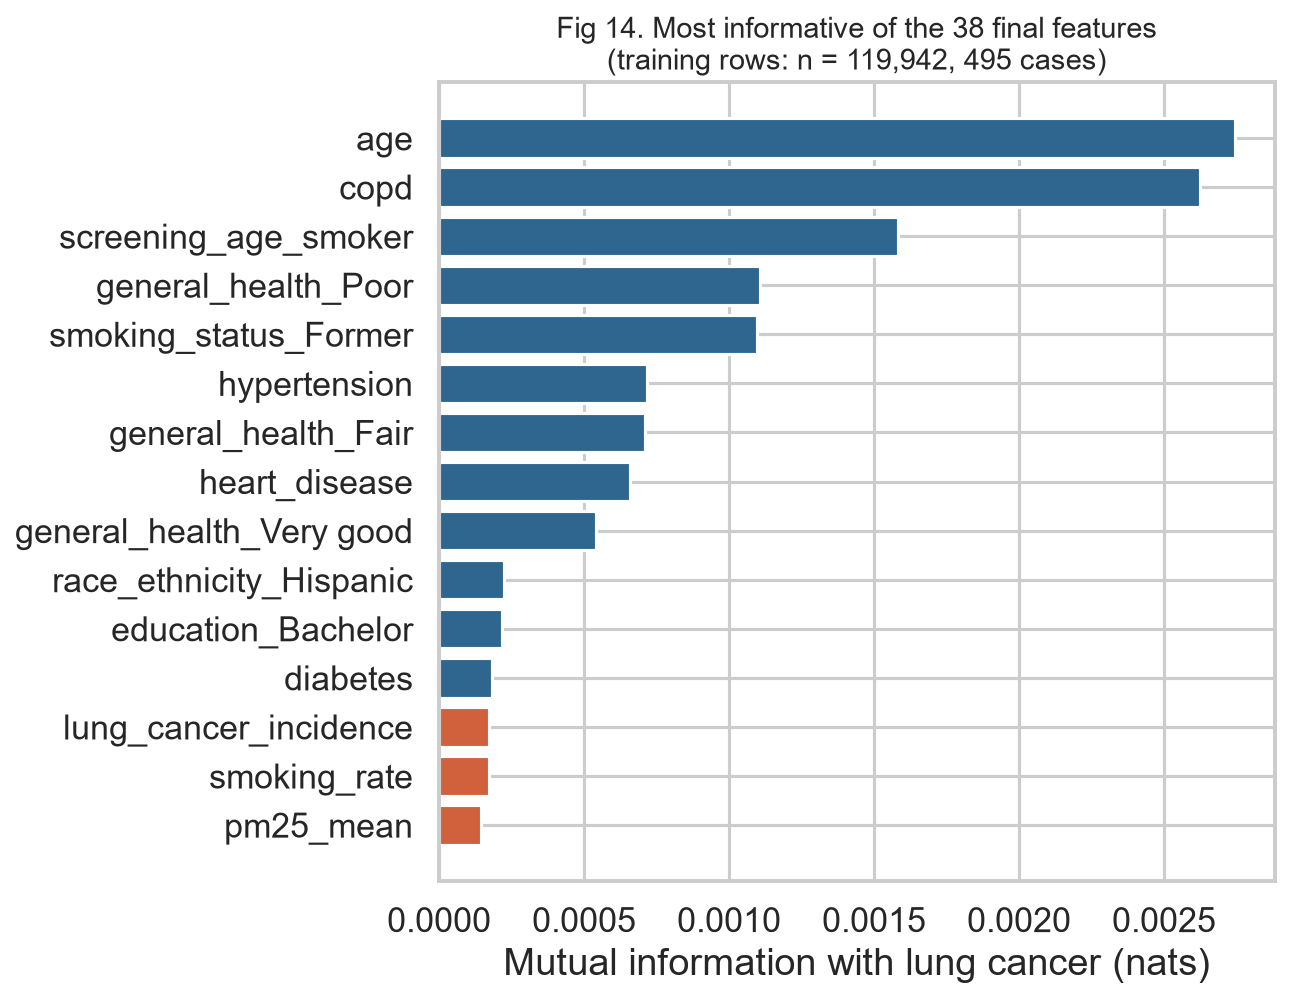

In [31]:
rank = eda.feature_relevance(mr)
show("fig14_feature_relevance", 600)

On the training rows, age (0.0027 nats), COPD (0.0026) and the screening-age-smoker flag (0.0016) carry the most
information, followed by poor health, former smoking and hypertension. The three regional columns are at the
bottom of the top 15 (0.00014–0.00017).

In [32]:
ri = eda.regional_mi_identity(mr, df)
mic = sup.mi_checked(mr)


Why the three regional MI values are (almost) equal:
                    column  distinct_values  region_year_cells  one_value_per_cell       mi                                       cells_sharing_a_value
                 pm25_mean               18                 20                True 0.000145 6.31 = West 2019 & West 2023; 7.43 = South 2022 & West 2021
              smoking_rate               20                 20                True 0.000173                                                            
     lung_cancer_incidence               20                 20                True 0.000173                                                            
region x year (cell label)               20                 20                True 0.000173                                                            
  As discrete columns, the regional values only say WHICH region-year an adult lives in. smoking_rate and
  lung_cancer_incidence take a different value in each of the 20 cells, so their

The regional MI values are almost identical for a structural reason: as discrete columns, `smoking_rate` and
`lung_cancer_incidence` take one value per region-year cell, so both equal the MI of the region-year label
(0.000173), and `pm25_mean` has two ties (18 values), so it is slightly lower. The three values measure one thing
— which region-year an adult lives in — so they cannot tell pollution, regional smoking and registry incidence
apart. Every listed feature beats the shuffled-target null; age and COPD carry about 10% of the target's entropy,
the regional columns about 0.5–0.6%.

### 5.5 Feature extraction: PCA

PCA - FEATURE EXTRACTION (fitted on training rows only)
Input: 38 selected features | 119,942 training rows | 29,986 test rows

Explained variance of the first 10 components:
component  eigenvalue  explained_variance_%  cumulative_%
      PC1        2.78                  7.30          7.30
      PC2        2.07                  5.44         12.74
      PC3        1.87                  4.91         17.65
      PC4        1.78                  4.68         22.34
      PC5        1.55                  4.08         26.42
      PC6        1.51                  3.98         30.40
      PC7        1.40                  3.68         34.08
      PC8        1.31                  3.45         37.53
      PC9        1.27                  3.35         40.88
     PC10        1.23                  3.23         44.11

PC1 explains 7.3% of the variance. If all 38 features were unrelated,
each component would explain about 2.6%.
Components needed for 80% of the variance: 24 of 38
Components needed for 9

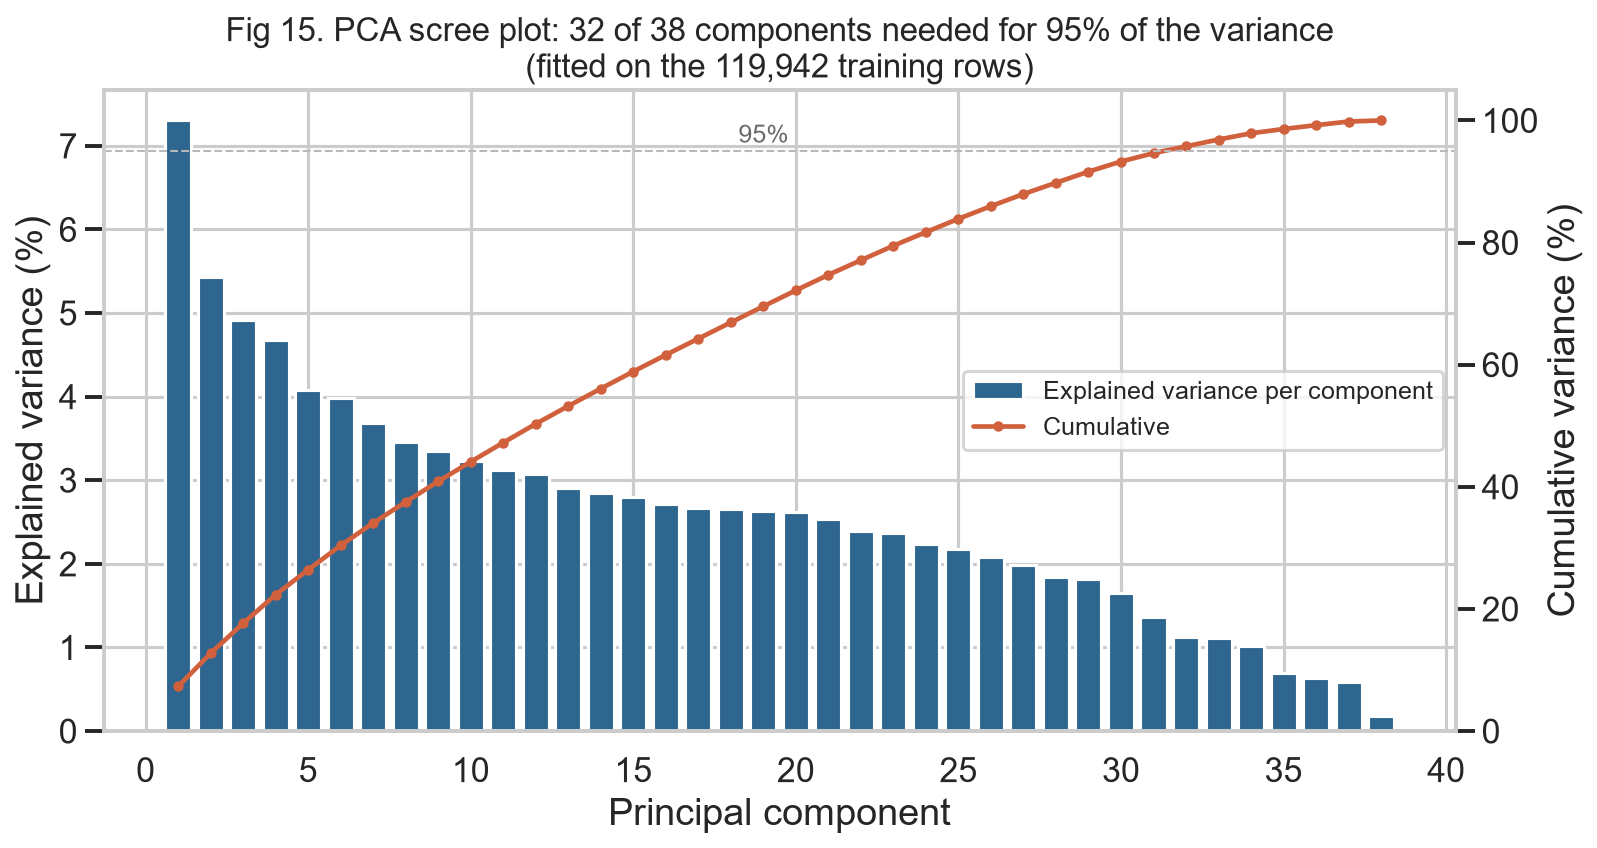

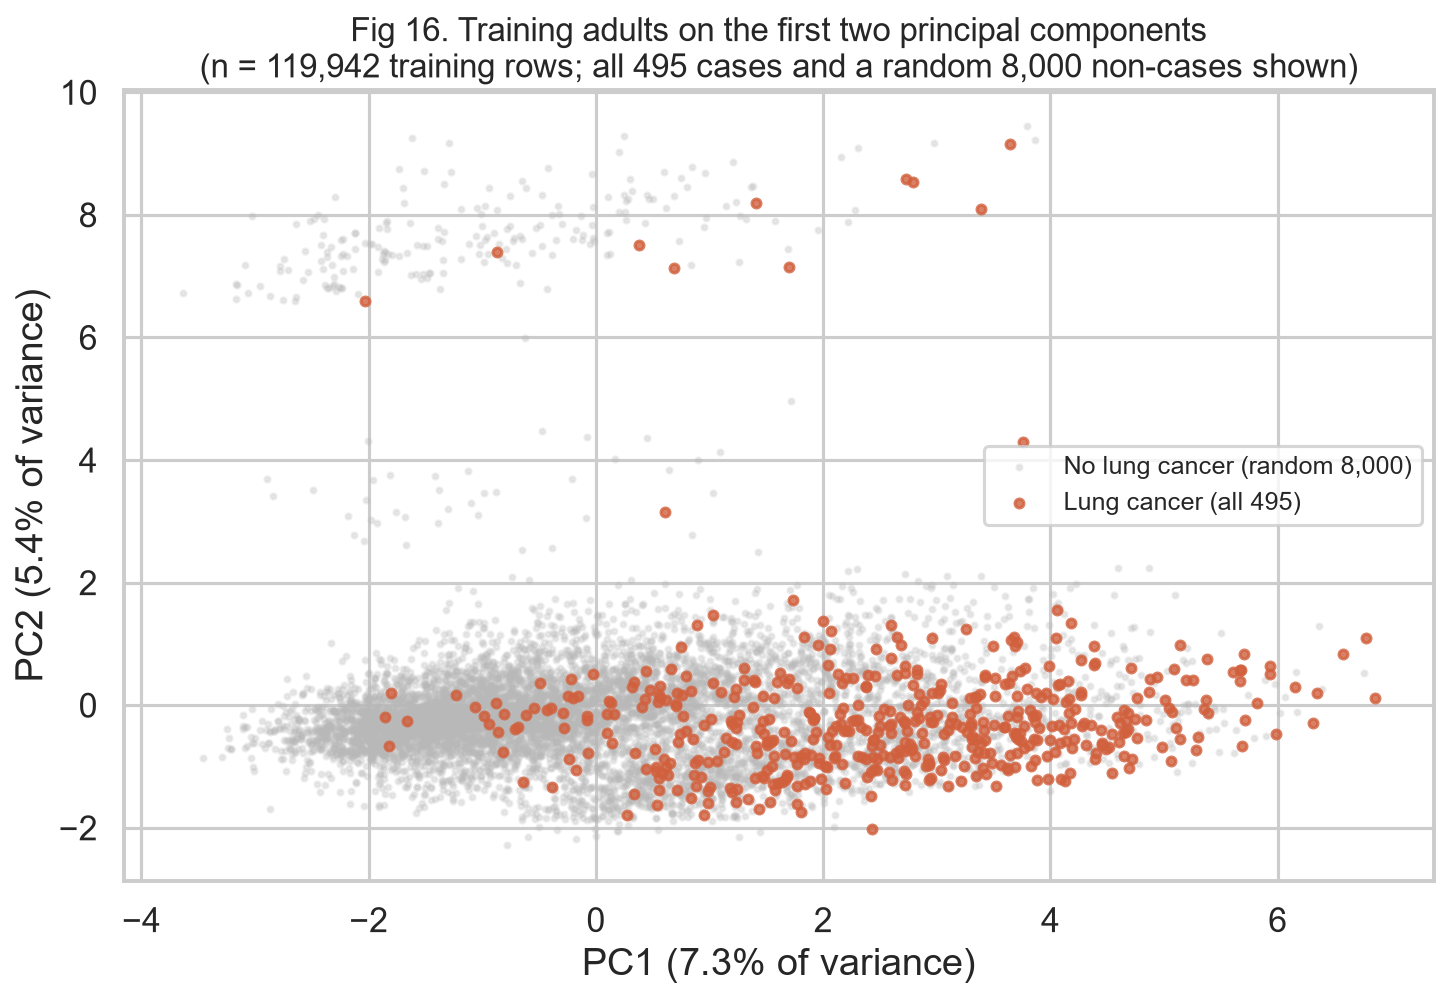

In [33]:
ev, loadings, pca, Z_train, k = fe.pca_analysis(mr)
fe.pca_figures(mr, pca, Z_train, k)
show("fig15_pca_scree", 750)
show("fig16_pca_projection", 650)

On the 38 features, PCA needs 24 / 29 / 32 components for 80 / 90 / 95% of the variance and no component has a
near-zero eigenvalue any more (there were 8 with the old 48 features — exactly the dependencies removed by rule
4). PC1 is age and chronic-disease burden, PC2 the "skipped the smoking questions" flags. The variance is spread
over many components, so we keep the original, interpretable features.

### 5.6 Final feature list and the success-criteria check

In [34]:
ff[ff.decision == 'KEEP'][['column', 'reason']].reset_index(drop=True)

,column,reason
0,age,risk rises strongly with age
1,screening_age_smoker,official high-risk group (age 50-80 and ever smoked)
2,screening_age_smoker_unknown,'unknown' flag: smoking status unknown (with ever_ecigarette_unknown it marks adults who skipped the smoking questio...
3,ever_ecigarette,health or lifestyle factor linked to lung cancer
4,ever_ecigarette_unknown,'unknown' flag: e-cigarette use unknown (mostly the same adults as screening_age_smoker_unknown); VIF 7.5 (below 10)
5,copd,"lung disease, strongly linked to lung cancer"
6,asthma,health or lifestyle factor linked to lung cancer
7,hypertension,health or lifestyle factor linked to lung cancer
8,heart_disease,health or lifestyle factor linked to lung cancer
9,diabetes,health or lifestyle factor linked to lung cancer


In [35]:
sc = eda.success_criteria(df, mr, tt)


10. SUCCESS CRITERIA CHECK (Phase 1 - measurable criteria)
                                                       criterion                                                             observed                   target  met
                       No duplicate person IDs in the clean file                                                                    0                        0 True
                       No missing values in the model-ready file                                                                    0                        0 True
                                      Regional join adds no rows                                                   149,928 -> 149,928                    equal True
Train and test keep the same lung cancer rate (stratified split)                                                       0.41% vs 0.41% difference < 0.05 points True
        Every research question has at least one hypothesis test {'RQ1': True, 'RQ2a': True, 'RQ2b': True, 'RQ2c': True,

All eight success criteria are met: no duplicates, no missing values in the model-ready file, a join that adds
no rows, the same 0.41% case rate in train and test, 18 Holm-corrected tests covering all five research
questions (RQ1 1, RQ2a 1, RQ2b 7, RQ2c 6, RQ3 3), a written reason for all 67 candidates, and no `CANEV_A`. Criterion 5 was asserted in Section 3.

## 6. Future steps (modelling phase — planned, not implemented)

1. **Baselines first:** the "always no" model and the USPSTF-style rule (`screening_age_smoker`), which on the
   test rows finds 66% of the cases with a precision of 1.25% (three times the base rate).
2. **Models:** class-weighted logistic regression on the 38 features (now free of exact collinearity, with the
   reference categories documented), then random forest and gradient boosting, tuned with stratified 5-fold
   cross-validation on training rows only.
3. **Metrics:** recall, precision, F1 and PR-AUC with a high-recall threshold, and calibration on the untouched
   test set — never accuracy.
4. **Ablations:** without the reverse-causation-prone features (general health, BMI, current smoking, the
   "ever told" conditions) and without the regional block; original features vs PCA components for
   distance-based models.
5. **Survey design:** extend the weighted, cluster-robust analysis to every association and to model evaluation.
6. **More NHIS variables:** age at diagnosis, family history of cancer, smoking intensity.
7. **Fairness:** compare recall across sex, race/ethnicity and income groups before anyone relies on a model.